In [ ]:
#Read geolocation data
import ee
import csv
import pandas as pd
from google.colab import drive

#Mount GDrive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
try:
    import geopandas
    import shapely
    import pyproj
    import folium
    import sklearn
    import hdbscan
    import libpysal
    # import esda
    print("All specified libraries are installed and ready to use.")

except ImportError as e:
    print(f"Error: One or more libraries are NOT installed.")
    print(f"Missing library: {e}")

# If the code runs without an error and prints the "All installed" message, you're good to go!

/usr/local/lib/python3.12/dist-packages/hdbscan/robust_single_linkage_.py:175: SyntaxWarning: invalid escape sequence '\{'
  $max \{ core_k(a), core_k(b), 1/\alpha d(a,b) \}$.


All specified libraries are installed and ready to use.


In [ ]:
%%capture
!pyproj
!pip install matplotlib-scalebar
!pip install contextily
!pip -q install alphashape
!pip -q install esda

Abidjan

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Abidjan/Final_datasets/abidjan_grid30m_master_merged_withDV.csv"
SITE_SHP = "/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/Abidjan/Abidjan_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 600          # target neighbourhood size (disjoint)
K_REG      = 55          # number of diagnostic regions 55
ANCHOR_CAP = 500          # max anchors
POOL_MAX   = 100_000      # for context-anchor preview/selection
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def farthest_point_sampling(xy, n, seed=42):
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = rng.integers(0, n_pts)
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, n):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lon(df["longitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy()
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys = []
counts = []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=11, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 60_000:
    nz = nz.sample(60_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 30_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m

Output hidden; open in https://colab.research.google.com to view.

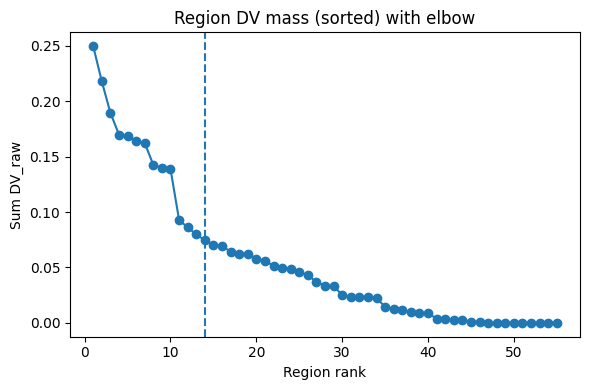

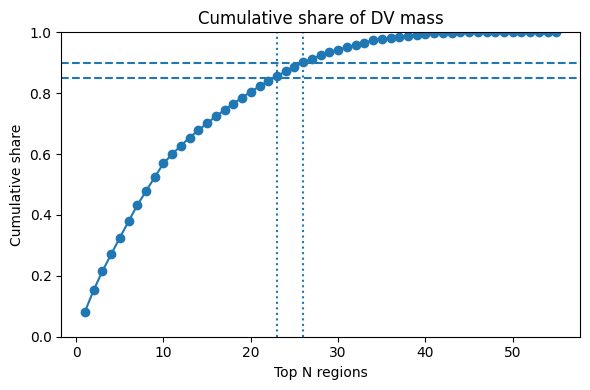

Elbow ≈ Top 14 regions (mass cutoff ≈ 0.0745).
Top 23 regions ≈ 85% of DV mass; Top 26 ≈ 90%.


In [ ]:
# ---- ELBOW ON REGION MASS (paste after regions_gdf/centers_gdf are built) ----
import numpy as np
import matplotlib.pyplot as plt

# sum DV by region and sort descending
mass = (gdf.groupby(REG_COL)["DV_raw"]
          .sum()
          .sort_values(ascending=False))
vals  = mass.values
ranks = np.arange(1, len(vals) + 1)

if vals.sum() == 0 or len(vals) < 2:
    print("Not enough or zero DV mass to compute an elbow.")
else:
    # elbow via max distance to line (first -> last)
    p1 = np.array([ranks[0], vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # cumulative share helpers (e.g., 85% / 90%)
    cumshare = np.cumsum(vals) / vals.sum()
    k85 = int(np.searchsorted(cumshare, 0.85)) + 1
    k90 = int(np.searchsorted(cumshare, 0.90)) + 1

    # 1) Mass (sorted) + elbow
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--')
    plt.title("Region DV mass (sorted) with elbow")
    plt.xlabel("Region rank")
    plt.ylabel("Sum DV_raw")
    plt.tight_layout()
    plt.show()

    # 2) Cumulative share curve
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    plt.axhline(0.85, linestyle='--')
    plt.axhline(0.90, linestyle='--')
    plt.axvline(k85, linestyle=':')
    plt.axvline(k90, linestyle=':')
    plt.ylim(0, 1)
    plt.title("Cumulative share of DV mass")
    plt.xlabel("Top N regions")
    plt.ylabel("Cumulative share")
    plt.tight_layout()
    plt.show()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    print(f"Top {k85} regions ≈ 85% of DV mass; Top {k90} ≈ 90%.")


In [ ]:
# --- installs (uncomment first time) ---
# !pip -q install geopandas shapely scikit-learn libpysal esda

import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Abidjan/Final_datasets/abidjan_grid30m_master_merged_withDV.csv"
PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m","civ_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55             # total K-means regions across city
TOP_K    = 30             # <-- analyze only the top-30 by DV mass
GLOBAL_SAMPLE_N = 20000   # DV-stratified sample size for the global RF (approx)
RANDOM_SEED = 42

# RF params
RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    """Stratify by DV deciles (only positive DV get their own deciles; zeros form their own stratum)."""
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
    parts = []
    # allocate half to positive, half to zeros (rebalance if one side is small)
    n_pos = min(len(pos), n // 2) if len(pos) > 0 else 0
    n_zero = n - n_pos
    if len(pos) > 0 and n_pos > 0:
        take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
        parts.append(pos.groupby("dv_dec", group_keys=False).apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    """GroupKFold by region groups; returns predictions, residuals, and Moran's I of residuals per fold."""
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all = [], []
    morans = []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)

        # Moran's I on residuals of this fold
        resid = y[te] - pred
        coords_te = coords[te]
        w = KNN.from_array(coords_te, k=8)
        w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(
        r2 = float(r2_score(y_true_all, y_pred_all)),
        mae = float(mean_absolute_error(y_true_all, y_pred_all))
    )
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# ========================= K-MEANS REGIONS & TOP-30 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
# DV-stratified + spatially balanced-ish (by deciles) sample
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PREDICTORS].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values  # blocked by regions

# scale predictors for permutation stability (RF doesn't need it to fit, but helps PI comparability)
scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PREDICTORS, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-30) =========================
region_reports = []
region_imps = []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    # safety: require enough points
    if len(sub) < 500:
        continue

    Xr = sub[PREDICTORS].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PREDICTORS, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    # simple in-sample fit stats (diagnostic)
    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-30 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

# Heterogeneity summary: CV of importances across Top-30
if not region_imps_df.empty:
    het = (region_imps_df
           .groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-30 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")

# # ========================= SAVE OPTIONAL OUTPUTS =========================
# OUT_DIR = Path("/content/outputs_abidjan_rf")
# OUT_DIR.mkdir(parents=True, exist_ok=True)

# global_imp.to_csv(OUT_DIR/"global_permutation_importance.csv", index=False)
# morans_df.to_csv(OUT_DIR/"global_cv_moransI.csv", index=False)
# region_reports.to_csv(OUT_DIR/"top30_region_fit_stats.csv", index=False)
# if not region_imps_df.empty:
#     region_imps_df.to_csv(OUT_DIR/"top30_region_permutation_importances.csv", index=False)

# print(f"\nFiles saved in: {OUT_DIR}")


Loaded 144,026 rows | UTM EPSG:32630 | non-zero DV: 67,329
Top-30 regions by DV mass: [8, 31, 20, 14, 28, 30, 21, 35, 51, 13] ...

=== GLOBAL RF ===
Permutation importance (top 10):
               feature  imp_mean  imp_std
      civ_general_2020  0.859713 0.029082
 spacing_median_m_250m  0.655212 0.015817
            rwi_interp  0.485537 0.010417
       dist_tertiary_m  0.291063 0.015668
   accessibility_index  0.286015 0.004170
          u18_bilinear  0.220811 0.005989
          ntl_bilinear  0.207787 0.005978
      dist_secondary_m  0.138486 0.005609
          slum_mean30m  0.087654 0.002584
clark_evans_R_net_250m  0.054823 0.001956

Blocked-CV metrics: {
  "r2": -0.05574768201038793,
  "mae": 3.117139201715376e-05
}

Moran's I of test residuals by fold:
 fold        I     p
    1 0.899126 0.001
    2 0.848986 0.001
    3 0.677795 0.001
    4 0.781729 0.001
    5 0.805263 0.001

=== PER-REGION RFs (Top-30 by mass) ===
 region    n       r2
      1 2312 0.980342
      6 3505 0.997698

In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Abidjan/Final_datasets/abidjan_grid30m_master_merged_withDV.csv"
PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m","civ_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55             # total K-means regions across city
TOP_K    = 30             # analyze only the top-K by DV mass
GLOBAL_SAMPLE_N = 20000   # DV-stratified sample size for the global RF (approx)
RANDOM_SEED = 42

# ---------------- NEIGHBOURHOOD SCALE (USER-DEFINED) ----------------
# Upper bound for each local RF support (neighbourhood scale)
MAX_AREA_KM2 = 1.0                 # <- user-defined upper bound (km^2)
GRID_RES_M   = 30                  # <- 30m grid
MIN_PIXELS   = 500                 # <- stability lower bound (grid points)

# Derived caps
MAX_RADIUS_M = float(np.sqrt((MAX_AREA_KM2 * 1e6) / np.pi))                # circular radius equivalent
MAX_PIXELS   = int((MAX_AREA_KM2 * 1e6) / (GRID_RES_M * GRID_RES_M))       # pixel-count backstop

print(f"[Config] Local RF support cap: {MAX_AREA_KM2:.2f} km² "
      f"(radius≈{MAX_RADIUS_M:.0f} m, max_pixels≈{MAX_PIXELS:,}) | min_pixels={MIN_PIXELS:,}")

# RF params
RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    """Stratify by DV deciles (only positive DV get their own deciles; zeros form their own stratum)."""
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
    parts = []
    # allocate half to positive, half to zeros (rebalance if one side is small)
    n_pos = min(len(pos), n // 2) if len(pos) > 0 else 0
    n_zero = n - n_pos
    if len(pos) > 0 and n_pos > 0:
        take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
        parts.append(pos.groupby("dv_dec", group_keys=False).apply(
            lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)
        ))
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    """GroupKFold by region groups; returns predictions, residuals, and Moran's I of residuals per fold."""
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all = [], []
    morans = []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)

        # Moran's I on residuals of this fold
        resid = y[te] - pred
        coords_te = coords[te]
        w = KNN.from_array(coords_te, k=8)
        w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(
        r2 = float(r2_score(y_true_all, y_pred_all)),
        mae = float(mean_absolute_error(y_true_all, y_pred_all))
    )
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

def apply_neighbourhood_cap(sub, x_col="x_utm", y_col="y_utm",
                            max_radius_m=MAX_RADIUS_M, max_pixels=MAX_PIXELS,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED):
    """
    Enforce neighbourhood-scale upper bound using a circular radius around the subset centroid,
    with a pixel-count backstop. Returns capped subset or None if below min_pixels.
    """
    if sub.empty:
        return None

    # centroid (UTM meters)
    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    # backstop: ensure we never exceed the area-derived pixel cap
    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
# DV-stratified + spatially balanced-ish (by deciles) sample
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PREDICTORS].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values  # blocked by regions

# scale predictors for permutation stability (RF doesn't need it to fit, but helps PI comparability)
scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PREDICTORS, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-K; neighbourhood-capped) =========================
region_reports = []
region_imps = []

for rid in top_regions:
    sub0 = gdf[gdf["region"] == rid]

    # Apply neighbourhood-scale upper bound (≤ MAX_AREA_KM2) + min support
    sub = apply_neighbourhood_cap(sub0)
    if sub is None:
        continue

    Xr = sub[PREDICTORS].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PREDICTORS, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    imp_r["n_used"] = len(sub)
    imp_r["radius_m"] = MAX_RADIUS_M
    imp_r["max_area_km2"] = MAX_AREA_KM2
    region_imps.append(imp_r)

    # simple in-sample fit stats (diagnostic)
    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-K by mass; neighbourhood-capped) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement after capping.")

# Heterogeneity summary: CV of importances across retained local models
if not region_imps_df.empty:
    het = (region_imps_df
           .groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across retained local models (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")

[Config] Local RF support cap: 1.00 km² (radius≈564 m, max_pixels≈1,111) | min_pixels=500
Loaded 144,026 rows | UTM EPSG:32630 | non-zero DV: 67,329
Top-30 regions by DV mass: [8, 31, 20, 14, 28, 30, 21, 35, 51, 13] ...

=== GLOBAL RF ===
Permutation importance (top 10):
               feature  imp_mean  imp_std
      civ_general_2020  0.859713 0.029082
 spacing_median_m_250m  0.655212 0.015817
            rwi_interp  0.485537 0.010417
       dist_tertiary_m  0.291063 0.015668
   accessibility_index  0.286015 0.004170
          u18_bilinear  0.220811 0.005989
          ntl_bilinear  0.207787 0.005978
      dist_secondary_m  0.138486 0.005609
          slum_mean30m  0.087654 0.002584
clark_evans_R_net_250m  0.054823 0.001956

Blocked-CV metrics: {
  "r2": -0.05574768201038793,
  "mae": 3.117139201715376e-05
}

Moran's I of test residuals by fold:
 fold        I     p
    1 0.899126 0.001
    2 0.848986 0.001
    3 0.677795 0.001
    4 0.781729 0.001
    5 0.805263 0.001

=== PER-REGION 

Accra

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CITY SWITCH ----------------
CITY = "Accra"  # <- change to "Abidjan", "Accra", etc.

def city_paths(city):
    c = city.lower()
    CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{city}/Final_datasets/{c}_grid30m_master_merged_withDV.csv"
    SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{city}/{city}_sites.shp"
    return CSV, SITE_SHP

CSV, SITE_SHP = city_paths(CITY)

# ---------------- CONFIG ----------------
PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 600          # target neighbourhood size (disjoint)
K_REG      = 55           # number of diagnostic regions
ANCHOR_CAP = 500          # max anchors
POOL_MAX   = 100_000      # for context-anchor preview/selection
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def farthest_point_sampling(xy, n, seed=42):
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = rng.integers(0, n_pts)
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, n):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"[{CITY}] Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lon(df["longitude"].mean())  # Accra ~ EPSG:32630
print(f"[{CITY}] Chosen UTM: {epsg}")

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print(f"\n[{CITY}] Site layer not found/loaded; skipping site anchors preview. {e}")

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy()
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys, counts = [], []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=11, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 60_000:
    nz = nz.sample(60_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 30_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m

Output hidden; open in https://colab.research.google.com to view.

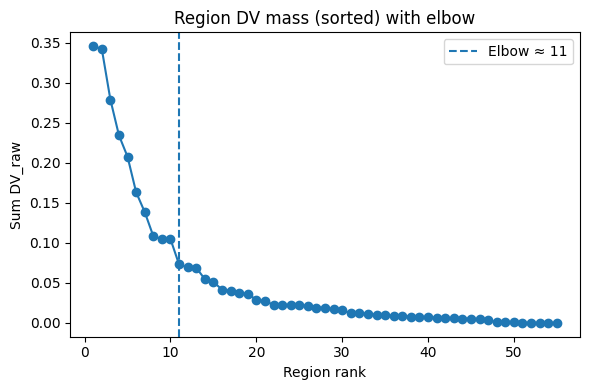

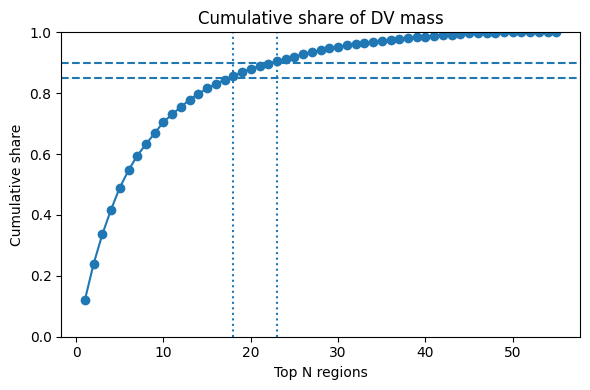

Elbow ≈ Top 11 regions (mass cutoff ≈ 0.073).
Top 18 regions ≈ 85% of DV mass.
Top 23 regions ≈ 90% of DV mass.
Top-30 region IDs by DV mass: [10, 11, 18, 54, 50, 41, 30, 42, 27, 38, 7, 37, 47, 53, 8, 39, 23, 28, 21, 17, 29, 0, 13, 19, 3, 40, 51, 15, 4, 2]


In [ ]:
# --- 2) DV-mass elbow for Accra (run after REG_COL & gdf with DV_raw exist) ---
import numpy as np
import matplotlib.pyplot as plt

def plot_dv_mass_elbow(gdf, REG_COL, pct_lines=(0.85, 0.90), return_ids=True):
    """Plot elbow on DV mass by region; also returns top-ID lists."""
    mass = (gdf.groupby(REG_COL)["DV_raw"]
              .sum()
              .sort_values(ascending=False))
    vals  = mass.values
    ranks = np.arange(1, len(vals) + 1)

    if vals.sum() == 0 or len(vals) < 2:
        print("Not enough or zero DV mass to compute an elbow.")
        return None

    # elbow via max distance to line (first -> last)
    p1 = np.array([ranks[0], vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # cumulative shares & convenient cutoffs
    cumshare = np.cumsum(vals) / vals.sum()
    cuts = {f"k{int(p*100)}": int(np.searchsorted(cumshare, p)) + 1 for p in pct_lines}

    # --- plots ---
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--', label=f"Elbow ≈ {elbow_k}")
    plt.title("Region DV mass (sorted) with elbow")
    plt.xlabel("Region rank"); plt.ylabel("Sum DV_raw")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p, k in cuts.items():
        plt.axhline(int(p[1:])/100, linestyle='--')
        plt.axvline(k, linestyle=':')
    plt.ylim(0, 1); plt.title("Cumulative share of DV mass")
    plt.xlabel("Top N regions"); plt.ylabel("Cumulative share")
    plt.tight_layout(); plt.show()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    for p, k in cuts.items():
        print(f"Top {k} regions ≈ {int(p[1:])}% of DV mass.")

    if return_ids:
        out = {
            "mass_series": mass,                 # sorted Series (index = region id)
            "elbow_k": elbow_k,
            "cutoff_mass": cutoff,
            **cuts,
            "top_ids_elbow": mass.index[:elbow_k].tolist(),
            "top_ids_85":   mass.index[:cuts.get("k85", 0)].tolist(),
            "top_ids_90":   mass.index[:cuts.get("k90", 0)].tolist(),
            "top_ids_30":   mass.index[:30].tolist(),   # handy for your Top-30 choice
        }
        return out

# ---- use it (Accra) ----
elbow_info = plot_dv_mass_elbow(gdf, REG_COL)
top30_ids  = elbow_info["top_ids_30"] if elbow_info else []
print("Top-30 region IDs by DV mass:", top30_ids)


In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
# Accra paths
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Accra/Final_datasets/accra_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "gha_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55              # total K-means regions across city
TOP_K    = 23              # <-- analyze only the top-23 by DV mass
GLOBAL_SAMPLE_N = 20000    # DV-stratified sample size for the global RF (approx)
RANDOM_SEED = 42

# RF params
RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    """Stratify by DV deciles (positives into deciles; zeros their own stratum)."""
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    parts = []
    n_pos = min(len(pos), n // 2) if len(pos) > 0 else 0
    n_zero = n - n_pos
    if len(pos) > 0 and n_pos > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
        parts.append(pos.groupby("dv_dec", group_keys=False).apply(
            lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)
        ))
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    return pd.concat(parts) if parts else g.head(min(n, len(g)))

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    """GroupKFold by region; returns metrics + Moran's I of residuals per fold."""
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all, morans = [], [], []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)

        resid = y[te] - pred
        w = KNN.from_array(coords[te], k=8); w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))

    y_true_all = np.concatenate(y_true_all); y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(r2=float(r2_score(y_true_all, y_pred_all)),
                   mae=float(mean_absolute_error(y_true_all, y_pred_all)))
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())  # Accra should resolve to EPSG:32630

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[Accra] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# ========================= K-MEANS REGIONS & TOP-23 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PREDICTORS].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values

scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PREDICTORS, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF (Accra) ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-23) =========================
region_reports, region_imps = [], []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    if len(sub) < 500:
        continue

    Xr = sub[PREDICTORS].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PREDICTORS, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-23 by DV mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

# Heterogeneity summary across Top-23
if not region_imps_df.empty:
    het = (region_imps_df
           .groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-23 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Accra] Loaded 614,158 rows | UTM EPSG:32630 | non-zero DV: 133,750
Top-23 regions by DV mass: [10, 11, 18, 54, 50, 41, 30, 42, 27, 38] ...

=== GLOBAL RF (Accra) ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
        accessibility_index  0.985130 0.007728
                 rwi_interp  0.351970 0.011211
           dist_secondary_m  0.326759 0.006906
               ntl_bilinear  0.325132 0.005489
      spacing_median_m_250m  0.276203 0.007114
mean_footprint_area_m2_250m  0.228093 0.002571
           gha_general_2020  0.178419 0.005774
               slum_mean30m  0.130379 0.003534
    built_environment_index  0.052283 0.000779
     clark_evans_R_net_250m  0.047198 0.001799

Blocked-CV metrics: {
  "r2": -0.1306543037514909,
  "mae": 1.3771014083756033e-05
}

Moran's I of test residuals by fold:
 fold        I     p
    1 0.786786 0.001
    2 0.655741 0.001
    3 0.823051 0.001
    4 0.804727 0.001
    5 0.913055 0.001

=== PER-REGION RFs (Top-23 by DV

In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
# Accra paths
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Accra/Final_datasets/accra_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "gha_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55              # total K-means regions across city
TOP_K    = 23              # analyze only the top-K by DV mass
GLOBAL_SAMPLE_N = 20000    # DV-stratified sample size for the global RF (approx)
RANDOM_SEED = 42

# ---------------- NEIGHBOURHOOD SCALE (USER-DEFINED) ----------------
# Upper bound for each local RF support (neighbourhood scale)
MAX_AREA_KM2 = 1.0                 # <- user-defined upper bound (km^2)
GRID_RES_M   = 30                  # <- 30m grid
MIN_PIXELS   = 500                 # <- existing stability lower bound (grid points)

# Derived caps
MAX_RADIUS_M = float(np.sqrt((MAX_AREA_KM2 * 1e6) / np.pi))                # circular radius equivalent
MAX_PIXELS   = int((MAX_AREA_KM2 * 1e6) / (GRID_RES_M * GRID_RES_M))       # pixel-count backstop

print(f"[Config] Local RF support cap: {MAX_AREA_KM2:.2f} km² "
      f"(radius≈{MAX_RADIUS_M:.0f} m, max_pixels≈{MAX_PIXELS:,}) | min_pixels={MIN_PIXELS:,}")

# RF params
RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    """Stratify by DV deciles (positives into deciles; zeros their own stratum)."""
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    parts = []
    n_pos = min(len(pos), n // 2) if len(pos) > 0 else 0
    n_zero = n - n_pos
    if len(pos) > 0 and n_pos > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
        parts.append(pos.groupby("dv_dec", group_keys=False).apply(
            lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)
        ))
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    return pd.concat(parts) if parts else g.head(min(n, len(g)))

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    """GroupKFold by region; returns metrics + Moran's I of residuals per fold."""
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all, morans = [], [], []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)

        resid = y[te] - pred
        w = KNN.from_array(coords[te], k=8); w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))

    y_true_all = np.concatenate(y_true_all); y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(r2=float(r2_score(y_true_all, y_pred_all)),
                   mae=float(mean_absolute_error(y_true_all, y_pred_all)))
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

def apply_neighbourhood_cap(sub, x_col="x_utm", y_col="y_utm",
                            max_radius_m=MAX_RADIUS_M, max_pixels=MAX_PIXELS,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED):
    """
    Enforce neighbourhood-scale upper bound using a circular radius around the subset centroid,
    with a pixel-count backstop. Returns capped subset or None if below min_pixels.
    """
    if sub.empty:
        return None

    # centroid (UTM meters)
    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    # backstop: ensure we never exceed the area-derived pixel cap
    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())  # Accra should resolve to EPSG:32630

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[Accra] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PREDICTORS].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values

scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PREDICTORS, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(
    Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5
)

print("\n=== GLOBAL RF (Accra) ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-K by DV mass) =========================
region_reports, region_imps = [], []

for rid in top_regions:
    sub0 = gdf[gdf["region"] == rid]

    # Apply neighbourhood-scale upper bound (≤ MAX_AREA_KM2) + min support
    sub = apply_neighbourhood_cap(sub0)
    if sub is None:
        continue

    Xr = sub[PREDICTORS].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PREDICTORS, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    imp_r["n_used"] = len(sub)
    imp_r["radius_m"] = MAX_RADIUS_M
    imp_r["max_area_km2"] = MAX_AREA_KM2
    region_imps.append(imp_r)

    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-K by DV mass; neighbourhood-capped) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement after capping.")

# Heterogeneity summary across retained regions
if not region_imps_df.empty:
    het = (region_imps_df
           .groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0, np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across retained local models (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Config] Local RF support cap: 1.00 km² (radius≈564 m, max_pixels≈1,111) | min_pixels=500
[Accra] Loaded 614,158 rows | UTM EPSG:32630 | non-zero DV: 133,750
Top-23 regions by DV mass: [10, 11, 18, 54, 50, 41, 30, 42, 27, 38] ...

=== GLOBAL RF (Accra) ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
        accessibility_index  0.985130 0.007728
                 rwi_interp  0.351970 0.011211
           dist_secondary_m  0.326759 0.006906
               ntl_bilinear  0.325132 0.005489
      spacing_median_m_250m  0.276203 0.007114
mean_footprint_area_m2_250m  0.228093 0.002571
           gha_general_2020  0.178419 0.005774
               slum_mean30m  0.130379 0.003534
    built_environment_index  0.052283 0.000779
     clark_evans_R_net_250m  0.047198 0.001799

Blocked-CV metrics: {
  "r2": -0.1306543037514909,
  "mae": 1.3771014083756033e-05
}

Moran's I of test residuals by fold:
 fold        I     p
    1 0.786786 0.001
    2 0.655741 0.001
    3 

Dakar

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Dakar/Final_datasets/dakar_grid30m_master_merged_withDV.csv"
SITE_SHP = "/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/Dakar/Dakar_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 600          # target neighbourhood size (disjoint)
K_REG      = 55           # number of diagnostic regions
ANCHOR_CAP = 500          # max anchors
POOL_MAX   = 100_000      # for context-anchor preview/selection
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def farthest_point_sampling(xy, n, seed=42):
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = rng.integers(0, n_pts)
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, n):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"[Dakar] Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lon(df["longitude"].mean())  # Dakar should resolve to EPSG:32628
print("[Dakar] Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\n[Dakar] Site layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy()
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys, counts = [], []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=11, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 60_000:
    nz = nz.sample(60_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 30_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m


Output hidden; open in https://colab.research.google.com to view.

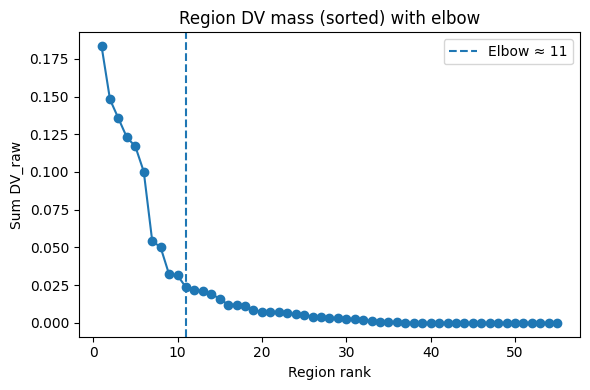

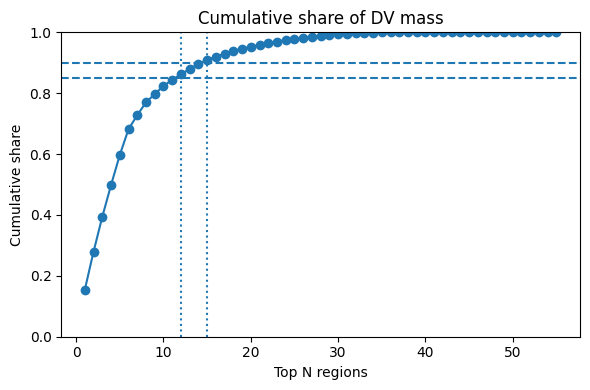

Elbow ≈ Top 11 regions (mass cutoff ≈ 0.0236).
Top 12 regions ≈ 85% of DV mass.
Top 15 regions ≈ 90% of DV mass.
Top-30 region IDs by DV mass: [12, 53, 54, 32, 0, 37, 28, 6, 51, 1, 21, 47, 14, 3, 41, 43, 39, 34, 36, 16, 13, 50, 40, 49, 52, 5, 31, 17, 46, 48]


In [ ]:
# --- 2) DV-mass elbow for Accra (run after REG_COL & gdf with DV_raw exist) ---
import numpy as np
import matplotlib.pyplot as plt

def plot_dv_mass_elbow(gdf, REG_COL, pct_lines=(0.85, 0.90), return_ids=True):
    """Plot elbow on DV mass by region; also returns top-ID lists."""
    mass = (gdf.groupby(REG_COL)["DV_raw"]
              .sum()
              .sort_values(ascending=False))
    vals  = mass.values
    ranks = np.arange(1, len(vals) + 1)

    if vals.sum() == 0 or len(vals) < 2:
        print("Not enough or zero DV mass to compute an elbow.")
        return None

    # elbow via max distance to line (first -> last)
    p1 = np.array([ranks[0], vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # cumulative shares & convenient cutoffs
    cumshare = np.cumsum(vals) / vals.sum()
    cuts = {f"k{int(p*100)}": int(np.searchsorted(cumshare, p)) + 1 for p in pct_lines}

    # --- plots ---
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--', label=f"Elbow ≈ {elbow_k}")
    plt.title("Region DV mass (sorted) with elbow")
    plt.xlabel("Region rank"); plt.ylabel("Sum DV_raw")
    plt.legend(); plt.tight_layout(); plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p, k in cuts.items():
        plt.axhline(int(p[1:])/100, linestyle='--')
        plt.axvline(k, linestyle=':')
    plt.ylim(0, 1); plt.title("Cumulative share of DV mass")
    plt.xlabel("Top N regions"); plt.ylabel("Cumulative share")
    plt.tight_layout(); plt.show()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    for p, k in cuts.items():
        print(f"Top {k} regions ≈ {int(p[1:])}% of DV mass.")

    if return_ids:
        out = {
            "mass_series": mass,                 # sorted Series (index = region id)
            "elbow_k": elbow_k,
            "cutoff_mass": cutoff,
            **cuts,
            "top_ids_elbow": mass.index[:elbow_k].tolist(),
            "top_ids_85":   mass.index[:cuts.get("k85", 0)].tolist(),
            "top_ids_90":   mass.index[:cuts.get("k90", 0)].tolist(),
            "top_ids_30":   mass.index[:30].tolist(),   # handy for your Top-30 choice
        }
        return out

# ---- use it (Accra) ----
elbow_info = plot_dv_mass_elbow(gdf, REG_COL)
top30_ids  = elbow_info["top_ids_30"] if elbow_info else []
print("Top-30 region IDs by DV mass:", top30_ids)

In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Dakar/Final_datasets/dakar_grid30m_master_merged_withDV.csv"
PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "sen_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55             # total K-means regions across city
TOP_K    = 15             # <-- analyze only the top-30 by DV mass
GLOBAL_SAMPLE_N = 20000   # DV-stratified sample size for the global RF (approx)
RANDOM_SEED = 42

# RF params
RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    """Stratify by DV deciles (only positive DV get their own deciles; zeros form their own stratum)."""
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
    parts = []
    # allocate half to positive, half to zeros (rebalance if one side is small)
    n_pos = min(len(pos), n // 2) if len(pos) > 0 else 0
    n_zero = n - n_pos
    if len(pos) > 0 and n_pos > 0:
        take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
        parts.append(pos.groupby("dv_dec", group_keys=False).apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    """GroupKFold by region groups; returns predictions, residuals, and Moran's I of residuals per fold."""
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all = [], []
    morans = []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)

        # Moran's I on residuals of this fold
        resid = y[te] - pred
        coords_te = coords[te]
        w = KNN.from_array(coords_te, k=8)
        w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(
        r2 = float(r2_score(y_true_all, y_pred_all)),
        mae = float(mean_absolute_error(y_true_all, y_pred_all))
    )
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# ========================= K-MEANS REGIONS & TOP-30 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
# DV-stratified + spatially balanced-ish (by deciles) sample
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PREDICTORS].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values  # blocked by regions

# scale predictors for permutation stability (RF doesn't need it to fit, but helps PI comparability)
scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PREDICTORS, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-30) =========================
region_reports = []
region_imps = []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    # safety: require enough points
    if len(sub) < 500:
        continue

    Xr = sub[PREDICTORS].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PREDICTORS, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    # simple in-sample fit stats (diagnostic)
    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-30 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

# Heterogeneity summary: CV of importances across Top-30
if not region_imps_df.empty:
    het = (region_imps_df
           .groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-30 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")

Loaded 207,848 rows | UTM EPSG:32628 | non-zero DV: 38,324
Top-15 regions by DV mass: [12, 53, 54, 32, 0, 37, 28, 6, 51, 1] ...

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
           sen_general_2020  0.685955 0.012492
                 rwi_interp  0.611521 0.017696
            dist_tertiary_m  0.354182 0.005766
           dist_secondary_m  0.327945 0.005401
               ntl_bilinear  0.281270 0.006300
mean_footprint_area_m2_250m  0.220779 0.009896
               u18_bilinear  0.170030 0.003339
               slum_mean30m  0.151569 0.001936
        accessibility_index  0.142315 0.002008
     clark_evans_R_net_250m  0.032445 0.001300

Blocked-CV metrics: {
  "r2": -0.1210657225933034,
  "mae": 1.871318387916349e-05
}

Moran's I of test residuals by fold:
 fold        I     p
    1 0.839842 0.001
    2 0.916833 0.001
    3 0.905495 0.001
    4 0.880782 0.001
    5 0.890904 0.001

=== PER-REGION RFs (Top-30 by mass) ===
 region    n 

In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CSV = "/content/drive/MyDrive/Results_2/Data_2024/Processed/Dakar/Final_datasets/dakar_grid30m_master_merged_withDV.csv"
PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "sen_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55             # total K-means regions across city
TOP_K    = 15             # analyze only the top-K by DV mass
GLOBAL_SAMPLE_N = 20000   # DV-stratified sample size for the global RF (approx)
RANDOM_SEED = 42

# ---------------- NEIGHBOURHOOD SCALE (USER-DEFINED) ----------------
# Upper bound for each local RF support (neighbourhood scale)
MAX_AREA_KM2 = 1.0                 # <- user-defined upper bound (km^2)
GRID_RES_M   = 30                  # <- 30m grid
MIN_PIXELS   = 500                 # <- stability lower bound (grid points)

# Derived caps
MAX_RADIUS_M = float(np.sqrt((MAX_AREA_KM2 * 1e6) / np.pi))                # circular radius equivalent
MAX_PIXELS   = int((MAX_AREA_KM2 * 1e6) / (GRID_RES_M * GRID_RES_M))       # pixel-count backstop

print(f"[Config] Local RF support cap: {MAX_AREA_KM2:.2f} km² "
      f"(radius≈{MAX_RADIUS_M:.0f} m, max_pixels≈{MAX_PIXELS:,}) | min_pixels={MIN_PIXELS:,}")

# RF params
RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    """Stratify by DV deciles (only positive DV get their own deciles; zeros form their own stratum)."""
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
    parts = []
    # allocate half to positive, half to zeros (rebalance if one side is small)
    n_pos = min(len(pos), n // 2) if len(pos) > 0 else 0
    n_zero = n - n_pos
    if len(pos) > 0 and n_pos > 0:
        take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
        parts.append(pos.groupby("dv_dec", group_keys=False).apply(
            lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)
        ))
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    """GroupKFold by region groups; returns predictions, residuals, and Moran's I of residuals per fold."""
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all = [], []
    morans = []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)

        # Moran's I on residuals of this fold
        resid = y[te] - pred
        coords_te = coords[te]
        w = KNN.from_array(coords_te, k=8)
        w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(
        r2 = float(r2_score(y_true_all, y_pred_all)),
        mae = float(mean_absolute_error(y_true_all, y_pred_all))
    )
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

def apply_neighbourhood_cap(sub, x_col="x_utm", y_col="y_utm",
                            max_radius_m=MAX_RADIUS_M, max_pixels=MAX_PIXELS,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED):
    """
    Enforce neighbourhood-scale upper bound using a circular radius around the subset centroid,
    with a pixel-count backstop. Returns capped subset or None if below min_pixels.
    """
    if sub.empty:
        return None

    # centroid (UTM meters)
    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    # backstop: ensure we never exceed the area-derived pixel cap
    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
# DV-stratified + spatially balanced-ish (by deciles) sample
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PREDICTORS].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values  # blocked by regions

# scale predictors for permutation stability (RF doesn't need it to fit, but helps PI comparability)
scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PREDICTORS, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-K; neighbourhood-capped) =========================
region_reports = []
region_imps = []

for rid in top_regions:
    sub0 = gdf[gdf["region"] == rid]

    # Apply neighbourhood-scale upper bound (≤ MAX_AREA_KM2) + min support
    sub = apply_neighbourhood_cap(sub0)
    if sub is None:
        continue

    Xr = sub[PREDICTORS].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PREDICTORS, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    imp_r["n_used"] = len(sub)
    imp_r["radius_m"] = MAX_RADIUS_M
    imp_r["max_area_km2"] = MAX_AREA_KM2
    region_imps.append(imp_r)

    # simple in-sample fit stats (diagnostic)
    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-K by mass; neighbourhood-capped) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement after capping.")

# Heterogeneity summary: CV of importances across retained local models
if not region_imps_df.empty:
    het = (region_imps_df
           .groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across retained local models (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")

[Config] Local RF support cap: 1.00 km² (radius≈564 m, max_pixels≈1,111) | min_pixels=500
Loaded 207,848 rows | UTM EPSG:32628 | non-zero DV: 38,324
Top-15 regions by DV mass: [12, 53, 54, 32, 0, 37, 28, 6, 51, 1] ...

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
           sen_general_2020  0.685955 0.012492
                 rwi_interp  0.611521 0.017696
            dist_tertiary_m  0.354182 0.005766
           dist_secondary_m  0.327945 0.005401
               ntl_bilinear  0.281270 0.006300
mean_footprint_area_m2_250m  0.220779 0.009896
               u18_bilinear  0.170030 0.003339
               slum_mean30m  0.151569 0.001936
        accessibility_index  0.142315 0.002008
     clark_evans_R_net_250m  0.032445 0.001300

Blocked-CV metrics: {
  "r2": -0.1210657225933034,
  "mae": 1.871318387916349e-05
}

Moran's I of test residuals by fold:
 fold        I     p
    1 0.839842 0.001
    2 0.916833 0.001
    3 0.905495 0.001
    4 

Freetown

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Freetown"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 600          # target neighbourhood size (disjoint)
K_REG      = 25           # number of diagnostic regions (tune per city if needed)
ANCHOR_CAP = 500          # max anchors
POOL_MAX   = 100_000      # for context-anchor preview/selection
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = rng.integers(0, n_pts)
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lon(df["longitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy() if context_needed > 0 else pd.DataFrame(columns=["x_utm","y_utm"])
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys = []
counts = []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=11, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 60_000:
    nz = nz.sample(60_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 30_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m


Output hidden; open in https://colab.research.google.com to view.

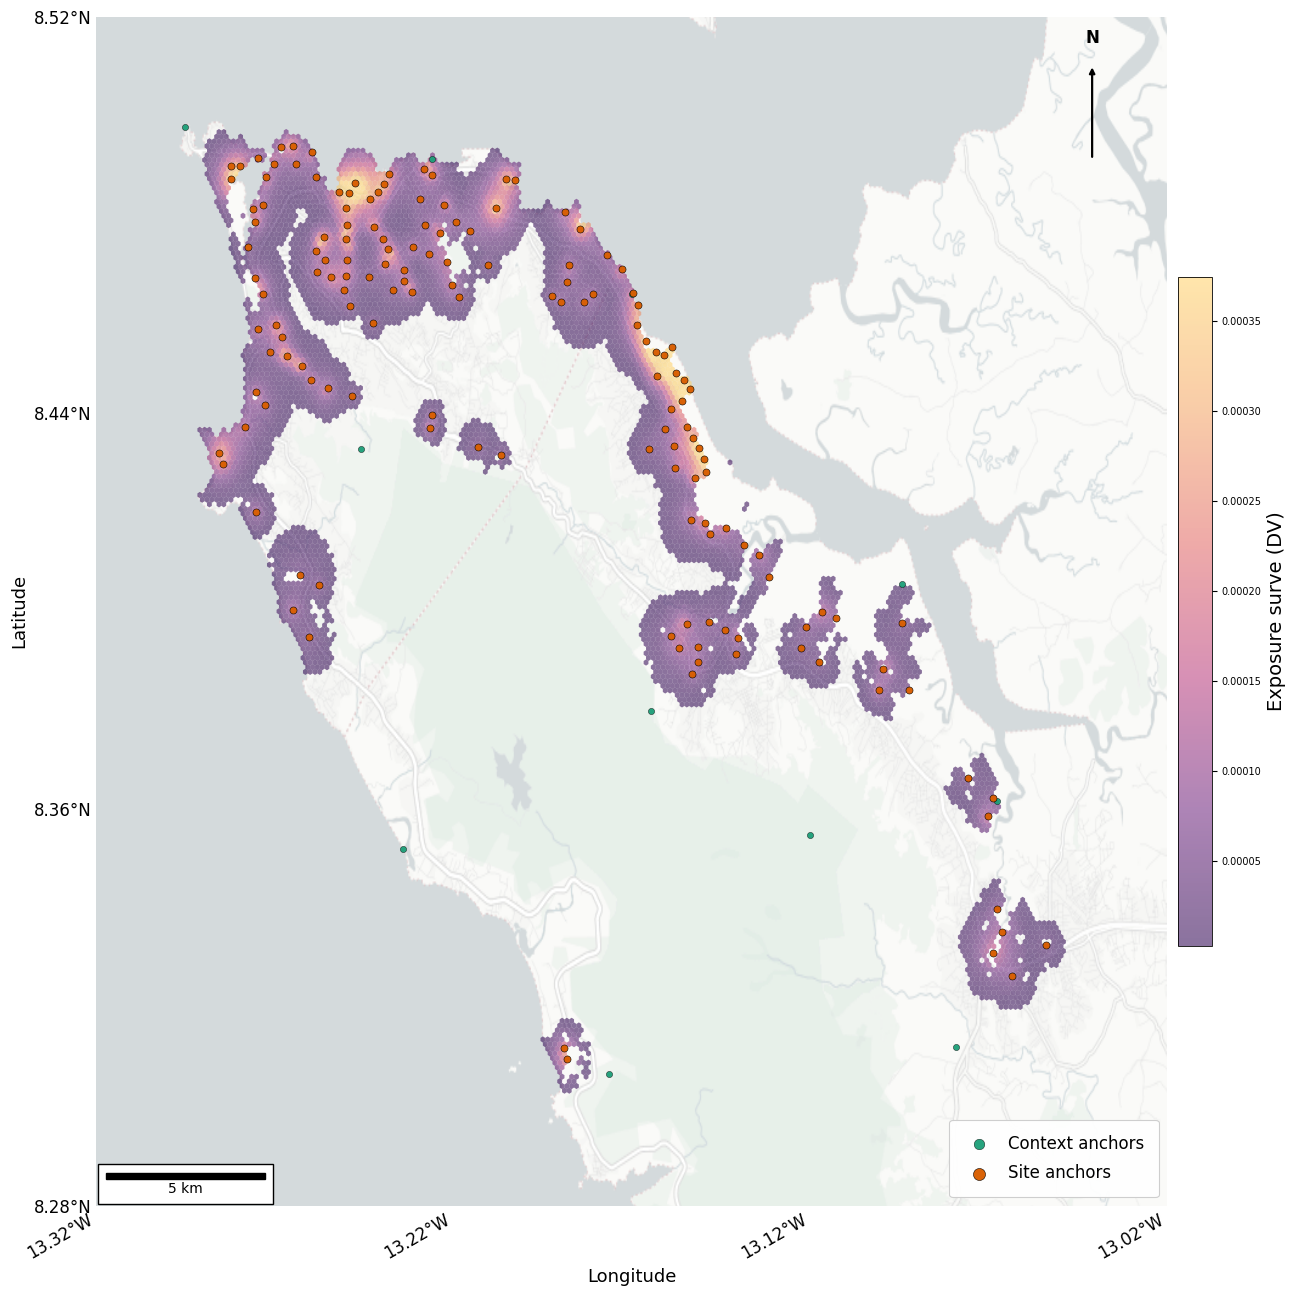

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint
import matplotlib.pyplot as plt
import matplotlib as mpl
import contextily as ctx
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
from pyproj import CRS, Transformer

# ---------------- CONFIG ----------------
CITY = "Freetown"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL = "DV_log1p"
H = 250.0
T_TARGET = 600
K_REG = 25
ANCHOR_CAP = 500
POOL_MAX = 100_000

# Custom colormap
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "exposure_plasma_soft",
    [
        "#2b004f",  # deep purple (low)
        "#6a1f7a",  # purple
        "#b63679",  # magenta
        "#e16462",  # orange-red
        "#f4a261",  # orange
        "#ffd166"   # pale yellow (high)
    ],
    N=256
)

# ---------------- HELPERS ----------------
# Add these imports at the top of the script
CRS_WEBMERC = CRS.from_epsg(3857)
CRS_WGS84 = CRS.from_epsg(4326)

def format_lon(lon):
    hemi = "E" if lon >= 0 else "W"
    return f"{abs(lon):.2f}°{hemi}"

def format_lat(lat):
    hemi = "N" if lat >= 0 else "S"
    return f"{abs(lat):.2f}°{hemi}"

def add_latlon_ticks(ax):
    """Convert current EPSG:3857 axes to lat/lon tick labels."""
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()

    transformer = Transformer.from_crs(CRS_WEBMERC, CRS_WGS84, always_xy=True)

    # choose 4 ticks each
    x_ticks = np.linspace(x_min, x_max, 4)
    y_ticks = np.linspace(y_min, y_max, 4)

    # use centre y for lon, centre x for lat
    y_c = (y_min + y_max) / 2.0
    x_c = (x_min + x_max) / 2.0

    lons = []
    for x in x_ticks:
        lon, _ = transformer.transform(x, y_c)
        lons.append(lon)

    lats = []
    for y in y_ticks:
        _, lat = transformer.transform(x_c, y)
        lats.append(lat)

    ax.set_xticks(x_ticks)
    ax.set_xticklabels([format_lon(lo) for lo in lons], fontsize=12)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels([format_lat(la) for la in lats], fontsize=12)

    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = rng.integers(0, n_pts)
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

def add_north_arrow(ax, x=0.92, y=0.90, size=0.08, text="N"):
    ax.annotate(
        "", xy=(x, y + size), xytext=(x, y),
        xycoords=ax.transAxes, textcoords=ax.transAxes,
        arrowprops=dict(arrowstyle="-|>", lw=1.6, color="black"),
        zorder=50
    )
    ax.text(
        x, y + size + 0.015, text,
        transform=ax.transAxes, ha="center", va="bottom",
        fontsize=12, fontweight="bold", color="black", zorder=51
    )

def add_scale_bar(ax, length_m=5000, location="lower left", pad=0.6):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(
        ax.transData,
        length_m,
        f"{int(length_m/1000)} km" if length_m >= 1000 else f"{int(length_m)} m",
        location,
        pad=pad,
        color="black",
        frameon=True,
        size_vertical=length_m * 0.03,
        fontproperties=fontprops
    )
    ax.add_artist(scalebar)

def create_exposure_map(gdf, anchors_gdf):
    # Work in Web Mercator for basemap + meters for scalebar
    gdf_3857 = gdf.to_crs(3857)

    anchors_gdf = gpd.GeoDataFrame(
        anchors_gdf,
        geometry=gpd.points_from_xy(anchors_gdf["x_utm"], anchors_gdf["y_utm"]),
        crs=gdf.crs
    ).to_crs(3857)

    # Exposure weights (clip at 99th percentile)
    gdf_3857["DV_w"] = gdf_3857["DV_raw"].astype(float)
    nz = gdf_3857[gdf_3857["DV_w"] > 0].copy()
    if len(nz) == 0:
        nz = gdf_3857.copy()
    q99 = nz["DV_w"].quantile(0.99) if len(nz) else 1.0
    nz["DV_w"] = nz["DV_w"].clip(upper=q99)

    # Optional thinning for speed
    MAX_PTS = 120_000
    if len(nz) > MAX_PTS:
        nz = nz.sample(MAX_PTS, random_state=42)

    # Compute map extent
    minx, miny, maxx, maxy = nz.total_bounds
    pad_x = (maxx - minx) * 0.12
    pad_y = (maxy - miny) * 0.12
    xlim = (minx - pad_x, maxx + pad_x)
    ylim = (miny - pad_y, maxy + pad_y)

    # Plotting
    fig, ax = plt.subplots(figsize=(13, 13)) ################################################

    # Basemap
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ctx.add_basemap(
        ax,
        source=ctx.providers.CartoDB.PositronNoLabels,
        attribution=False,
        zorder=0
    )

    # Hexbin with custom colormap
    hb = ax.hexbin(
        nz.geometry.x.values,
        nz.geometry.y.values,
        C=nz["DV_w"].values,
        reduce_C_function=np.mean,
        gridsize=180,
        mincnt=1,
        linewidths=0,
        alpha=0.55,
        cmap=exposure_cmap,  # Use the custom colormap
        zorder=5
    )

    # Colorbar
    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surve (DV)", fontsize=14)

    # Anchors
    is_site = anchors_gdf["anchor_type"].astype(str).eq("site")
    ax.scatter(
        anchors_gdf.loc[~is_site, "geometry"].x,
        anchors_gdf.loc[~is_site, "geometry"].y,
        s=20, marker="o",
        edgecolor="black", linewidth=0.3,
        facecolor="#1b9e77",
        alpha=0.95,
        zorder=20,
        label="Context anchors"
    )
    ax.scatter(
        anchors_gdf.loc[is_site, "geometry"].x,
        anchors_gdf.loc[is_site, "geometry"].y,
        s=26, marker="o",
        edgecolor="black", linewidth=0.4,
        facecolor="#d95f02",
        alpha=0.98,
        zorder=21,
        label="Site anchors"
    )

    # --- North arrow and scale bar ---
    add_north_arrow(ax, x=0.93, y=0.88, size=0.08)
    add_scale_bar(ax, length_m=5000, location="lower left")

    # --- Ticks/labels MUST come after limits are final ---
    add_latlon_ticks(ax)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

    # --- Keep axes ON so ticks show ---
    # ax.set_axis_off()   # <-- REMOVE this
    # If you want a clean frame but still want ticks:
    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(axis="both", which="both", length=0)  # optional: hide tick marks
    # ax.legend(loc="upper left", frameon=True)
    leg = ax.legend(
    loc="lower right",
    frameon=True,
    fontsize=12,
    markerscale=1.7,
    handlelength=1.8,
    labelspacing=0.7,
    borderpad=0.9
    )

    leg.get_frame().set_linewidth(0.8)
    leg.get_frame().set_alpha(0.95)

    plt.tight_layout()
    plt.show()

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

# [Rest of the data loading and preprocessing code remains the same as in previous scripts]
epsg = utm_epsg_for_lon(df["longitude"].mean())
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# Anchor selection
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy() if context_needed > 0 else pd.DataFrame(columns=["x_utm","y_utm"])
context_anchors["anchor_type"] = "context"

# Combine anchors
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

# Call the visualization function
create_exposure_map(gdf, anchors)

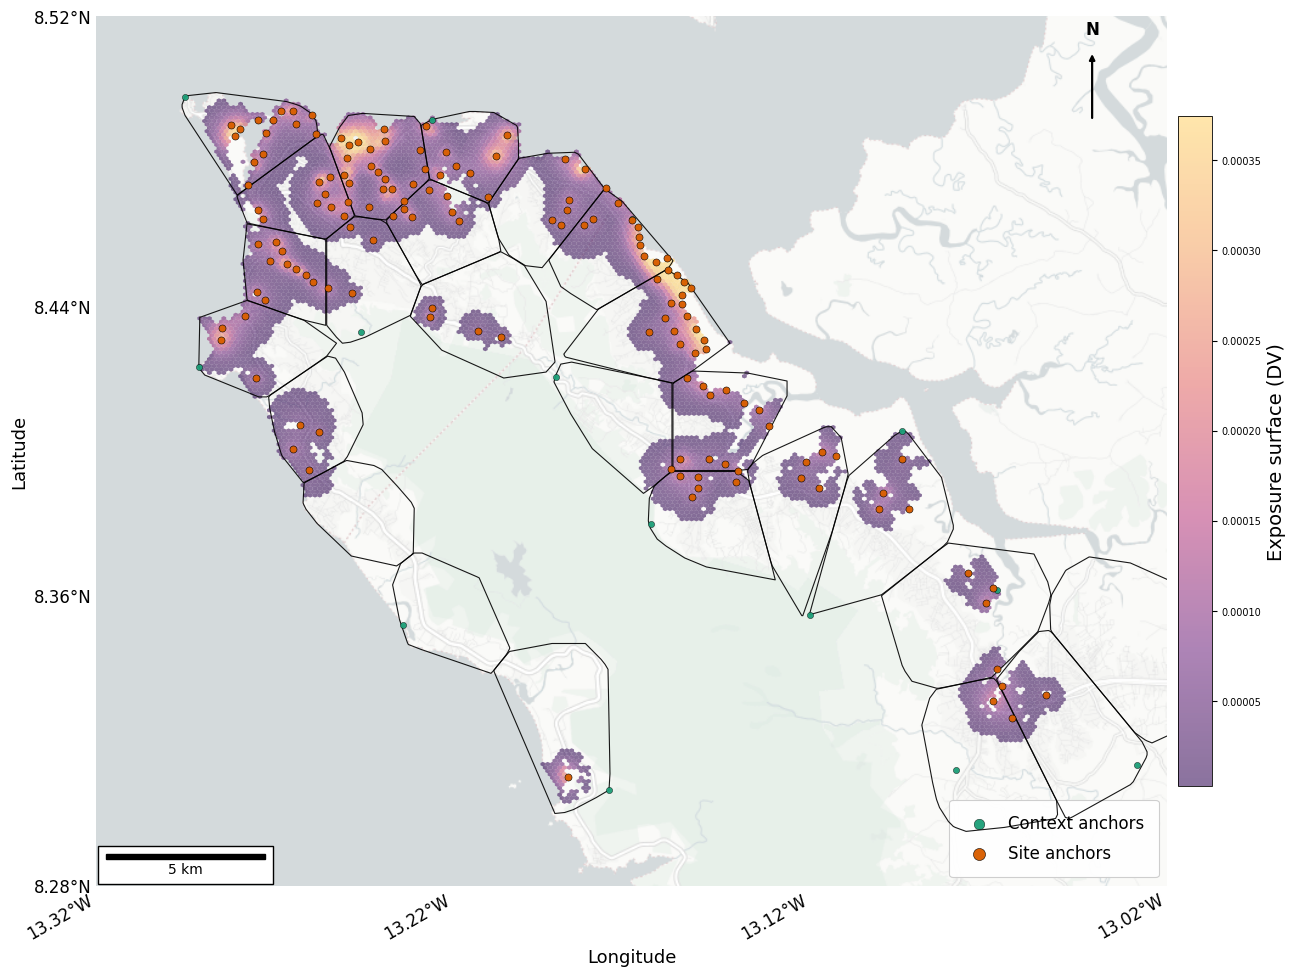

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint
import matplotlib.pyplot as plt
import contextily as ctx
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
from pyproj import CRS, Transformer

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Freetown"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL = "DV_log1p"
H = 250.0
T_TARGET = 600
K_REG = 25
ANCHOR_CAP = 500
POOL_MAX = 100_000

PALETTE = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# Custom colormap
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "exposure_plasma_soft",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# ---------------- CRS ----------------
CRS_WEBMERC = CRS.from_epsg(3857)
CRS_WGS84   = CRS.from_epsg(4326)

# ---------------- HELPERS ----------------
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = rng.integers(0, n_pts)
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

def format_lon(lon):
    hemi = "E" if lon >= 0 else "W"
    return f"{abs(lon):.2f}°{hemi}"

def format_lat(lat):
    hemi = "N" if lat >= 0 else "S"
    return f"{abs(lat):.2f}°{hemi}"

def add_latlon_ticks(ax):
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    transformer = Transformer.from_crs(CRS_WEBMERC, CRS_WGS84, always_xy=True)

    x_ticks = np.linspace(x_min, x_max, 4)
    y_ticks = np.linspace(y_min, y_max, 4)

    y_c = (y_min + y_max) / 2.0
    x_c = (x_min + x_max) / 2.0

    lons = [transformer.transform(x, y_c)[0] for x in x_ticks]
    lats = [transformer.transform(x_c, y)[1] for y in y_ticks]

    ax.set_xticks(x_ticks)
    ax.set_xticklabels([format_lon(lo) for lo in lons], fontsize=12)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels([format_lat(la) for la in lats], fontsize=12)

    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

def add_north_arrow(ax, x=0.92, y=0.90, size=0.08, text="N"):
    ax.annotate(
        "", xy=(x, y + size), xytext=(x, y),
        xycoords=ax.transAxes, textcoords=ax.transAxes,
        arrowprops=dict(arrowstyle="-|>", lw=1.6, color="black"),
        zorder=60
    )
    ax.text(
        x, y + size + 0.015, text,
        transform=ax.transAxes, ha="center", va="bottom",
        fontsize=12, fontweight="bold", color="black", zorder=61
    )

def add_scale_bar(ax, length_m=5000, location="lower left", pad=0.6):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(
        ax.transData,
        length_m,
        f"{int(length_m/1000)} km" if length_m >= 1000 else f"{int(length_m)} m",
        location,
        pad=pad,
        color="black",
        frameon=True,
        size_vertical=length_m * 0.03,
        fontproperties=fontprops
    )
    ax.add_artist(scalebar)

# ---------------- PLOT FUNCTION ----------------
def create_exposure_map_with_kmeans_regions(gdf_utm, anchors_df):
    """
    gdf_utm: GeoDataFrame in UTM CRS with columns x_utm,y_utm,DV_raw
    anchors_df: DataFrame with x_utm,y_utm,anchor_type
    """

    # --- KMEANS REGIONS (same as your pasted code) ---
    REG_COL = f"region_k{K_REG}"
    km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
    gdf_utm = gdf_utm.copy()
    gdf_utm[REG_COL] = km.fit_predict(gdf_utm[["x_utm","y_utm"]].values)

    # Convex hull per region (UTM)
    polys = []
    for rid in sorted(gdf_utm[REG_COL].unique()):
        sub = gdf_utm.loc[gdf_utm[REG_COL] == rid, ["x_utm","y_utm"]].values
        if len(sub) >= 3:
            polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
    regions_utm = gpd.GeoDataFrame(polys, crs=gdf_utm.crs)

    # --- Reproject everything to Web Mercator for plotting ---
    gdf_3857 = gdf_utm.to_crs(3857)
    regions_3857 = regions_utm.to_crs(3857)

    anchors_3857 = gpd.GeoDataFrame(
        anchors_df,
        geometry=gpd.points_from_xy(anchors_df["x_utm"], anchors_df["y_utm"]),
        crs=gdf_utm.crs
    ).to_crs(3857)

    # --- Exposure weights (clip at 99th percentile) ---
    gdf_3857["DV_w"] = gdf_3857["DV_raw"].astype(float)
    nz = gdf_3857[gdf_3857["DV_w"] > 0].copy()
    if len(nz) == 0:
        nz = gdf_3857.copy()

    q99 = nz["DV_w"].quantile(0.99) if len(nz) else 1.0
    nz["DV_w"] = nz["DV_w"].clip(upper=q99)

    # Optional thinning for speed
    MAX_PTS = 120_000
    if len(nz) > MAX_PTS:
        nz = nz.sample(MAX_PTS, random_state=42)

    # Extent from exposure points
    minx, miny, maxx, maxy = nz.total_bounds
    pad_x = (maxx - minx) * 0.12
    pad_y = (maxy - miny) * 0.12
    xlim = (minx - pad_x, maxx + pad_x)
    ylim = (miny - pad_y, maxy + pad_y)

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(13, 13))

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    ctx.add_basemap(
        ax,
        source=ctx.providers.CartoDB.PositronNoLabels,
        attribution=False,
        zorder=0
    )

    # Exposure surface
    hb = ax.hexbin(
        nz.geometry.x.values,
        nz.geometry.y.values,
        C=nz["DV_w"].values,
        reduce_C_function=np.mean,
        gridsize=180,
        mincnt=1,
        linewidths=0,
        alpha=0.55,
        cmap=exposure_cmap,
        zorder=5
    )
    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    # K-means region hull outlines (colored)
    regions_3857.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8,
    alpha=0.9,
    zorder=12
    )

    # Anchors
    is_site = anchors_3857["anchor_type"].astype(str).eq("site")
    ax.scatter(
        anchors_3857.loc[~is_site, "geometry"].x,
        anchors_3857.loc[~is_site, "geometry"].y,
        s=20, marker="o",
        edgecolor="black", linewidth=0.3,
        facecolor="#1b9e77",
        alpha=0.95,
        zorder=20,
        label="Context anchors"
    )
    ax.scatter(
        anchors_3857.loc[is_site, "geometry"].x,
        anchors_3857.loc[is_site, "geometry"].y,
        s=26, marker="o",
        edgecolor="black", linewidth=0.4,
        facecolor="#d95f02",
        alpha=0.98,
        zorder=21,
        label="Site anchors"
    )

    # North arrow + scalebar
    add_north_arrow(ax, x=0.93, y=0.88, size=0.08)
    add_scale_bar(ax, length_m=5000, location="lower left")

    # Lat/lon ticks
    add_latlon_ticks(ax)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

    # Clean spines but keep ticks
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    # Legend
    leg = ax.legend(
        loc="lower right",
        frameon=True,
        fontsize=12,
        markerscale=1.7,
        handlelength=1.8,
        labelspacing=0.7,
        borderpad=0.9
    )
    leg.get_frame().set_linewidth(0.8)
    leg.get_frame().set_alpha(0.95)

    plt.tight_layout()
    plt.show()

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

epsg = utm_epsg_for_lon(df["longitude"].mean())
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs="EPSG:4326"
).to_crs(epsg)

gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL].astype(float))

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid

    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)

    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"

except Exception as e:
    print("Site layer not found/loaded; continuing with context anchors only.", e)

rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)

context_anchors = (
    pool.iloc[sel_idx][["x_utm","y_utm"]].copy()
    if context_needed > 0 else
    pd.DataFrame(columns=["x_utm","y_utm"])
)
context_anchors["anchor_type"] = "context"

if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(
            x_utm=site_anchors.geometry.x,
            y_utm=site_anchors.geometry.y
        )[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

# ---------------- PLOT ----------------
create_exposure_map_with_kmeans_regions(gdf, anchors)


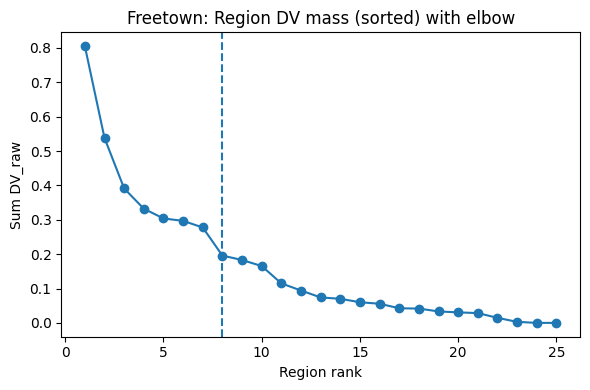

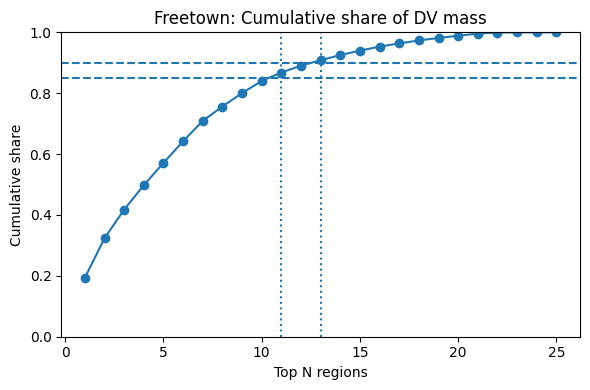

Elbow ≈ Top 8 regions (mass cutoff ≈ 0.196).
Top 11 regions ≈ 85% of DV mass.
Top 13 regions ≈ 90% of DV mass.


In [ ]:
# ---- ELBOW ON REGION MASS (Freetown-ready) ----
import numpy as np
import matplotlib.pyplot as plt

CITY = "Freetown"  # only for titles; does not affect logic
USE_LOGY = False    # set True if mass is very heavy-tailed
PCT_LINES = (0.85, 0.90)

# Sum DV by region and sort descending
mass = (gdf.groupby(REG_COL)["DV_raw"]
          .sum()
          .sort_values(ascending=False))
vals  = mass.values
ranks = np.arange(1, len(vals) + 1)

if vals.sum() == 0 or len(vals) < 2:
    print("Not enough or zero DV mass to compute an elbow.")
else:
    # Elbow via max distance to line (first -> last)
    p1 = np.array([ranks[0], vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # Cumulative share helpers (e.g., 85% / 90%)
    cumshare = np.cumsum(vals) / vals.sum()
    kP = {int(p*100): int(np.searchsorted(cumshare, p)) + 1 for p in PCT_LINES}

    # 1) Mass (sorted) + elbow
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--')
    if USE_LOGY:
        plt.yscale("symlog")
    plt.title(f"{CITY}: Region DV mass (sorted) with elbow")
    plt.xlabel("Region rank")
    plt.ylabel("Sum DV_raw")
    plt.tight_layout()
    plt.show()

    # 2) Cumulative share curve
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p in PCT_LINES:
        plt.axhline(p, linestyle='--')
        plt.axvline(kP[int(p*100)], linestyle=':')
    plt.ylim(0, 1)
    plt.title(f"{CITY}: Cumulative share of DV mass")
    plt.xlabel("Top N regions")
    plt.ylabel("Cumulative share")
    plt.tight_layout()
    plt.show()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    for pct, k in kP.items():
        print(f"Top {k} regions ≈ {pct}% of DV mass.")


In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Freetown"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "sle_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55             # total K-means regions across city (tune if needed)
TOP_K    = 11             # <-- analyze only the top-11 by DV mass
GLOBAL_SAMPLE_N = 20_000  # DV-stratified sample size for the global RF (approx)
RANDOM_SEED = 42

# RF params
RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    """Stratify by DV deciles (positives in deciles; zeros their own stratum)."""
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()

    parts = []
    # split target roughly half/half; rebalance if one side is small
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        n_pos = min(len(pos), n // 2)
        if n_pos > 0:
            take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
            parts.append(pos.groupby("dv_dec", group_keys=False)
                           .apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    else:
        n_pos = 0

    n_zero = n - n_pos
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))

    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    """GroupKFold by region groups; returns metrics and per-fold Moran's I of residuals."""
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all = [], []
    morans = []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)

        # Moran's I on residuals
        resid = y[te] - pred
        coords_te = coords[te]
        w = KNN.from_array(coords_te, k=8)
        w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(
        r2 = float(r2_score(y_true_all, y_pred_all)),
        mae = float(mean_absolute_error(y_true_all, y_pred_all))
    )
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# Adapt predictors to what's available
missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing:
    print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-11 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions)

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PRED_USE].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values  # blocked by regions

# scale predictors for permutation stability (RF fit is scale-free)
scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PRED_USE, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(14).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-11) =========================
region_reports = []
region_imps = []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    # safety: require enough points (tune threshold if Freetown regions are small)
    if len(sub) < 500:
        continue

    Xr = sub[PRED_USE].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PRED_USE, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    # simple in-sample fit stats (diagnostic)
    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-11 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

# Heterogeneity summary: CV of importances across Top-11
if not region_imps_df.empty:
    het = (region_imps_df
           .groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-11 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Freetown] Loaded 134,087 rows | UTM EPSG:32628 | non-zero DV: 68,445
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'sle_general_2020']
Top-11 regions by DV mass: [28, 30, 6, 53, 11, 5, 40, 2, 10, 12, 46]

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
           dist_secondary_m  7.160921 0.108810
        accessibility_index  1.627577 0.029730
                 rwi_interp  0.415507 0.010026
      spacing_median_m_250m  0.377241 0.007469
            dist_tertiary_m  0.295010 0.005003
               ntl_bilinear  0.232441 0.004618
    built_environment_index  0.150731 0.008757
   dist_to_mask_edge_m_250m  0.088043 0.002373
               u18_bilinear  0.076377 0.002252
mean_

In [ ]:
import math, warnings
import numpy as np, pandas as pd, geopandas as gpd
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Freetown"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "sle_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 55
TOP_K    = 11
RANDOM_SEED = 42

# Local RF params (only local results requested)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ---------------- MULTI-RUN NEIGHBOURHOOD AREAS (km^2) ----------------
MAX_AREA_LIST_KM2 = [3.0, 2.0, 1.0]   # <- outputs tables for each value
GRID_RES_M   = 30
MIN_PIXELS   = 500

# ========================= HELPERS =========================
def utm_epsg_for_lon(lon):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone}"

def perm_importance_table(model, X, y, feature_names, n_repeats=8, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def apply_neighbourhood_cap(sub, max_radius_m, max_pixels, min_pixels=MIN_PIXELS, seed=RANDOM_SEED,
                            x_col="x_utm", y_col="y_utm"):
    """Cap subset to a circular neighbourhood around its centroid; then apply pixel-count backstop."""
    if sub.empty:
        return None

    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

def run_local_rf_for_area(gdf, pred_use, top_regions, max_area_km2):
    """Run local RFs for a given neighbourhood max area; return per-region report + heterogeneity table."""
    max_radius_m = float(np.sqrt((max_area_km2 * 1e6) / np.pi))
    max_pixels   = int((max_area_km2 * 1e6) / (GRID_RES_M * GRID_RES_M))

    print(f"\n--- Local RF: MAX_AREA_KM2={max_area_km2:.1f} "
          f"(radius≈{max_radius_m:.0f} m, max_pixels≈{max_pixels:,}) ---")

    region_reports, region_imps = [], []

    for rid in top_regions:
        sub0 = gdf[gdf["region"] == rid]
        sub  = apply_neighbourhood_cap(sub0, max_radius_m=max_radius_m, max_pixels=max_pixels)
        if sub is None:
            continue

        Xr = sub[pred_use].values
        yr = sub[DV_COL].values

        scaler_r = StandardScaler().fit(Xr)
        Xr_s = scaler_r.transform(Xr)

        rf_r = RandomForestRegressor(**RF_REGION)
        rf_r.fit(Xr_s, yr)

        imp_r = perm_importance_table(rf_r, Xr_s, yr, pred_use, n_repeats=8, seed=RANDOM_SEED)
        imp_r["region"] = rid
        imp_r["n_used"] = len(sub)
        imp_r["radius_m"] = max_radius_m
        imp_r["max_area_km2"] = max_area_km2
        region_imps.append(imp_r)

        r2 = rf_r.score(Xr_s, yr)
        region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

    region_reports_df = pd.DataFrame(region_reports).sort_values("region") if region_reports else pd.DataFrame()
    region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

    if not region_imps_df.empty:
        het = (region_imps_df
               .groupby("feature")["imp_mean"]
               .agg(["mean","std"])
               .rename(columns={"mean":"imp_mean","std":"imp_std"})
               .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0, np.nan))))
        het = het.sort_values("cv", ascending=False).reset_index()
        het["max_area_km2"] = max_area_km2
    else:
        het = pd.DataFrame()

    return region_reports_df, region_imps_df, het

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lon(df["longitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# Adapt predictors to what's available
missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing:
    print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions)

# ========================= LOCAL RF: RUN FOR 3/2/1 km² =========================
all_region_reports = []
all_heterogeneity = []
all_region_imps = []

for a in MAX_AREA_LIST_KM2:
    rep_df, imps_df, het_df = run_local_rf_for_area(gdf, PRED_USE, top_regions, max_area_km2=a)

    # Print per-area region summary + heterogeneity table
    print("\nPer-region diagnostics (r2 is in-sample):")
    print(rep_df.to_string(index=False) if not rep_df.empty else "No regions met size requirement after capping.")

    print("\nImportance heterogeneity (sorted by CV):")
    if not het_df.empty:
        print(het_df[["feature","imp_mean","imp_std","cv","max_area_km2"]].round(3).to_string(index=False))
    else:
        print("(Empty)")

    # store outputs
    if not rep_df.empty:
        rep_df = rep_df.copy()
        rep_df["max_area_km2"] = a
        all_region_reports.append(rep_df)
    if not het_df.empty:
        all_heterogeneity.append(het_df)
    if not imps_df.empty:
        all_region_imps.append(imps_df)

# ========================= OPTIONAL: COMBINED TABLES =========================
combined_region_reports = pd.concat(all_region_reports, ignore_index=True) if all_region_reports else pd.DataFrame()
combined_heterogeneity  = pd.concat(all_heterogeneity, ignore_index=True) if all_heterogeneity else pd.DataFrame()
combined_region_imps    = pd.concat(all_region_imps, ignore_index=True) if all_region_imps else pd.DataFrame()

print("\n\n=== COMBINED HETEROGENEITY (all areas) ===")
if not combined_heterogeneity.empty:
    print(combined_heterogeneity[["max_area_km2","feature","imp_mean","imp_std","cv"]]
          .sort_values(["max_area_km2","cv"], ascending=[False, False])
          .round(3).to_string(index=False))
else:
    print("(Empty)")

# ========================= OPTIONAL: SAVE OUTPUTS =========================
# outdir = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Local_RF_Sensitivity"
# Path(outdir).mkdir(parents=True, exist_ok=True)
# combined_region_reports.to_csv(f"{outdir}/{CITY.lower()}_localrf_region_reports_3_2_1km2.csv", index=False)
# combined_heterogeneity.to_csv(f"{outdir}/{CITY.lower()}_localrf_heterogeneity_3_2_1km2.csv", index=False)
# combined_region_imps.to_csv(f"{outdir}/{CITY.lower()}_localrf_importances_by_region_3_2_1km2.csv", index=False)


[Freetown] Loaded 134,087 rows | UTM EPSG:32628 | non-zero DV: 68,445
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'sle_general_2020']
Top-11 regions by DV mass: [28, 30, 6, 53, 11, 5, 40, 2, 10, 12, 46]

--- Local RF: MAX_AREA_KM2=3.0 (radius≈977 m, max_pixels≈3,333) ---

Per-region diagnostics (r2 is in-sample):
 region  n_used       r2
      2    2719 0.995509
      5    2607 0.997326
      6    2360 0.999026
     10    2525 0.999142
     11    2495 0.997296
     12    2158 0.999212
     28    2289 0.997939
     30    2330 0.999331
     40    2497 0.997643
     46    2401 0.998011
     53    2723 0.998246

Importance heterogeneity (sorted by CV):
                    feature  imp_mean  imp_std    cv  max_area_km2
      

Johannesburg

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Johannesburg"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 800          # target neighbourhood size (Johannesburg is larger)
K_REG      = 80           # number of diagnostic regions (larger city)
ANCHOR_CAP = 800          # max anchors
POOL_MAX   = 200_000      # for context-anchor preview/selection
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lonlat(lon, lat):
    """Return EPSG for UTM zone with correct hemisphere."""
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = int(rng.integers(0, n_pts))
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"[{CITY}] Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy() if context_needed > 0 else pd.DataFrame(columns=["x_utm","y_utm"])
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys = []
counts = []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=10, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 120_000:
    nz = nz.sample(120_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 50_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m

Output hidden; open in https://colab.research.google.com to view.

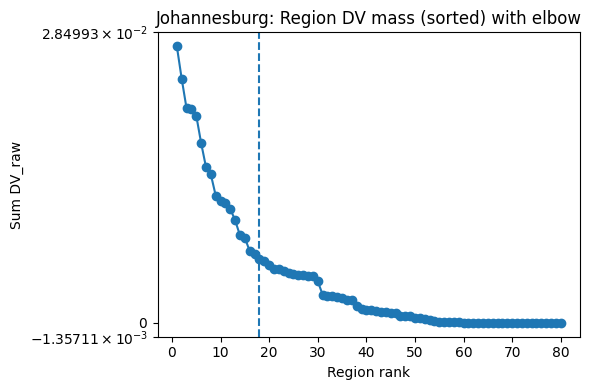

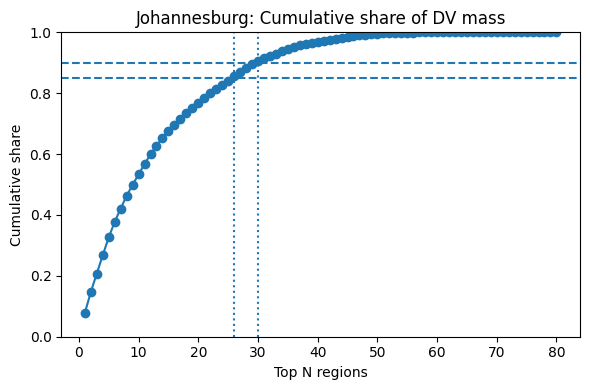

Elbow ≈ Top 18 regions (mass cutoff ≈ 0.00624).
Top 26 regions ≈ 85% of DV mass.
Top 30 regions ≈ 90% of DV mass.

Selected region lists:
  top_regions_elbow: [4, 68, 73, 74, 49, 35, 25, 26, 2, 55, 38, 79, 66, 57, 6] ...
  top_regions_85   : [4, 68, 73, 74, 49, 35, 25, 26, 2, 55, 38, 79, 66, 57, 6] ...
  top_regions_90   : [4, 68, 73, 74, 49, 35, 25, 26, 2, 55, 38, 79, 66, 57, 6] ...


In [ ]:
# ---- ELBOW ON REGION MASS (Johannesburg) ----
import numpy as np
import matplotlib.pyplot as plt

CITY = "Johannesburg"   # titles only
USE_LOGY = True         # Jo'burg often heavy-tailed; flip to False if you prefer
PCT_LINES = (0.85, 0.90)

# Sum DV by region and sort descending
mass = (gdf.groupby(REG_COL)["DV_raw"]
          .sum()
          .sort_values(ascending=False))
vals  = mass.values
ranks = np.arange(1, len(vals) + 1)

if vals.sum() == 0 or len(vals) < 2:
    print("Not enough or zero DV mass to compute an elbow.")
else:
    # Elbow via max distance to line (first -> last)
    p1 = np.array([ranks[0], vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # Cumulative share helpers (e.g., 85% / 90%)
    cumshare = np.cumsum(vals) / vals.sum()
    kP = {int(p*100): int(np.searchsorted(cumshare, p)) + 1 for p in PCT_LINES}

    # 1) Mass (sorted) + elbow
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--')
    if USE_LOGY:
        plt.yscale("symlog")
    plt.title(f"{CITY}: Region DV mass (sorted) with elbow")
    plt.xlabel("Region rank")
    plt.ylabel("Sum DV_raw")
    plt.tight_layout()
    plt.show()

    # 2) Cumulative share curve
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p in PCT_LINES:
        plt.axhline(p, linestyle='--')
        plt.axvline(kP[int(p*100)], linestyle=':')
    plt.ylim(0, 1)
    plt.title(f"{CITY}: Cumulative share of DV mass")
    plt.xlabel("Top N regions")
    plt.ylabel("Cumulative share")
    plt.tight_layout()
    plt.show()

    # Lists you can pass into the RF step
    top_regions_elbow = mass.index[:elbow_k].tolist()
    top_regions_85    = mass.index[:kP[85]].tolist() if 85 in kP else []
    top_regions_90    = mass.index[:kP[90]].tolist() if 90 in kP else []

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    for pct, k in kP.items():
        print(f"Top {k} regions ≈ {pct}% of DV mass.")
    print("\nSelected region lists:")
    print("  top_regions_elbow:", top_regions_elbow[:15], "..." if len(top_regions_elbow) > 15 else "")
    print("  top_regions_85   :", top_regions_85[:15], "..." if len(top_regions_85) > 15 else "")
    print("  top_regions_90   :", top_regions_90[:15], "..." if len(top_regions_90) > 15 else "")

    # Choose a default for downstream steps:
    top_regions = top_regions_elbow


In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Johannesburg"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "zaf_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 80              # Jo'burg is large; use more regions
TOP_K    = 30              # <-- analyze only the top-30 by DV mass
GLOBAL_SAMPLE_N = 20_000
RANDOM_SEED = 42

RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    parts = []
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        n_pos = min(len(pos), n // 2)
        if n_pos > 0:
            take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
            parts.append(pos.groupby("dv_dec", group_keys=False)
                           .apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    else:
        n_pos = 0
    n_zero = n - n_pos
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all, morans = [], [], []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)
        resid = y[te] - pred
        w = KNN.from_array(coords[te], k=8); w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all); y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(r2=float(r2_score(y_true_all, y_pred_all)),
                   mae=float(mean_absolute_error(y_true_all, y_pred_all)))
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing: print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-30 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PRED_USE].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values

scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PRED_USE, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-30) =========================
region_reports, region_imps = [], []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    if len(sub) < 500:
        continue
    Xr = sub[PRED_USE].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PRED_USE, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-30 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

if not region_imps_df.empty:
    het = (region_imps_df.groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-30 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Johannesburg] Loaded 41,454 rows | UTM EPSG:32735 | non-zero DV: 6,591
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'zaf_general_2020']
Top-30 regions by DV mass: [4, 68, 73, 74, 49, 35, 25, 26, 2, 55] ...

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
mean_footprint_area_m2_250m  0.588435 0.008091
        accessibility_index  0.449251 0.004914
      spacing_median_m_250m  0.373180 0.008581
               ntl_bilinear  0.179756 0.006555
               slum_mean30m  0.134387 0.002912
                 rwi_interp  0.133801 0.002420
           zaf_general_2020  0.126489 0.002189
           dist_secondary_m  0.105926 0.004351
     clark_evans_R_net_250m  0.090926 0.002540
  

In [ ]:
import math, warnings
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Johannesburg"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "zaf_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 80              # Jo'burg is large; use more regions
TOP_K    = 30              # analyze only the top-K by DV mass
RANDOM_SEED = 42

# Local RF params (only local results requested)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5,
                 random_state=RANDOM_SEED, n_jobs=-1)

# ---------------- MULTI-RUN NEIGHBOURHOOD AREAS (km^2) ----------------
MAX_AREA_LIST_KM2 = [5.0, 4.0, 6.0]   # <- outputs tables for each value
GRID_RES_M   = 30
MIN_PIXELS   = 500

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def perm_importance_table(model, X, y, feature_names, n_repeats=8, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats,
                               random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names,
                       "imp_mean": r.importances_mean,
                       "imp_std":  r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def apply_neighbourhood_cap(sub, max_radius_m, max_pixels,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED,
                            x_col="x_utm", y_col="y_utm"):
    """Cap subset to a circular neighbourhood around its centroid; then apply pixel-count backstop."""
    if sub.empty:
        return None

    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

def run_local_rf_for_area(gdf, pred_use, top_regions, max_area_km2):
    """Run local RFs for a given neighbourhood max area; return per-region report + heterogeneity table."""
    max_radius_m = float(np.sqrt((max_area_km2 * 1e6) / np.pi))
    max_pixels   = int((max_area_km2 * 1e6) / (GRID_RES_M * GRID_RES_M))

    print(f"\n--- Local RF: MAX_AREA_KM2={max_area_km2:.1f} "
          f"(radius≈{max_radius_m:.0f} m, max_pixels≈{max_pixels:,}) ---")

    region_reports, region_imps = [], []

    for rid in top_regions:
        sub0 = gdf[gdf["region"] == rid]
        sub  = apply_neighbourhood_cap(sub0, max_radius_m=max_radius_m, max_pixels=max_pixels)
        if sub is None:
            continue

        Xr = sub[pred_use].values
        yr = sub[DV_COL].values

        scaler_r = StandardScaler().fit(Xr)
        Xr_s = scaler_r.transform(Xr)

        rf_r = RandomForestRegressor(**RF_REGION)
        rf_r.fit(Xr_s, yr)

        imp_r = perm_importance_table(rf_r, Xr_s, yr, pred_use, n_repeats=8, seed=RANDOM_SEED)
        imp_r["region"] = rid
        imp_r["n_used"] = len(sub)
        imp_r["radius_m"] = max_radius_m
        imp_r["max_area_km2"] = max_area_km2
        region_imps.append(imp_r)

        r2 = rf_r.score(Xr_s, yr)  # in-sample diagnostic
        region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

    region_reports_df = pd.DataFrame(region_reports).sort_values("region") if region_reports else pd.DataFrame()
    region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

    if not region_imps_df.empty:
        het = (region_imps_df
               .groupby("feature")["imp_mean"]
               .agg(["mean","std"])
               .rename(columns={"mean":"imp_mean","std":"imp_std"})
               .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0, np.nan))))
        het = het.sort_values("cv", ascending=False).reset_index()
        het["max_area_km2"] = max_area_km2
    else:
        het = pd.DataFrame()

    return region_reports_df, region_imps_df, het

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                       crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# Adapt predictors to what's available
missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing:
    print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= LOCAL RF: RUN FOR 3/2/1 km² =========================
all_region_reports = []
all_heterogeneity = []
all_region_imps = []

for a in MAX_AREA_LIST_KM2:
    rep_df, imps_df, het_df = run_local_rf_for_area(gdf, PRED_USE, top_regions, max_area_km2=a)

    print("\nPer-region diagnostics (r2 is in-sample):")
    print(rep_df.to_string(index=False) if not rep_df.empty else "No regions met size requirement after capping.")

    print("\nImportance heterogeneity (sorted by CV):")
    if not het_df.empty:
        print(het_df[["feature","imp_mean","imp_std","cv","max_area_km2"]].round(3).to_string(index=False))
    else:
        print("(Empty)")

    # store outputs
    if not rep_df.empty:
        rep_df = rep_df.copy()
        rep_df["max_area_km2"] = a
        all_region_reports.append(rep_df)
    if not het_df.empty:
        all_heterogeneity.append(het_df)
    if not imps_df.empty:
        all_region_imps.append(imps_df)

# ========================= OPTIONAL: COMBINED TABLES =========================
combined_region_reports = pd.concat(all_region_reports, ignore_index=True) if all_region_reports else pd.DataFrame()
combined_heterogeneity  = pd.concat(all_heterogeneity, ignore_index=True) if all_heterogeneity else pd.DataFrame()
combined_region_imps    = pd.concat(all_region_imps, ignore_index=True) if all_region_imps else pd.DataFrame()

print("\n\n=== COMBINED HETEROGENEITY (all areas) ===")
if not combined_heterogeneity.empty:
    print(combined_heterogeneity[["max_area_km2","feature","imp_mean","imp_std","cv"]]
          .sort_values(["max_area_km2","cv"], ascending=[False, False])
          .round(3).to_string(index=False))
else:
    print("(Empty)")

# ========================= OPTIONAL: SAVE OUTPUTS =========================
# outdir = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Local_RF_Sensitivity"
# Path(outdir).mkdir(parents=True, exist_ok=True)
# combined_region_reports.to_csv(f"{outdir}/{CITY.lower()}_localrf_region_reports_3_2_1km2.csv", index=False)
# combined_heterogeneity.to_csv(f"{outdir}/{CITY.lower()}_localrf_heterogeneity_3_2_1km2.csv", index=False)
# combined_region_imps.to_csv(f"{outdir}/{CITY.lower()}_localrf_importances_by_region_3_2_1km2.csv", index=False)


[Johannesburg] Loaded 41,454 rows | UTM EPSG:32735 | non-zero DV: 6,591
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'zaf_general_2020']
Top-30 regions by DV mass: [4, 68, 73, 74, 49, 35, 25, 26, 2, 55] ...

--- Local RF: MAX_AREA_KM2=5.0 (radius≈1262 m, max_pixels≈5,555) ---

Per-region diagnostics (r2 is in-sample):
No regions met size requirement after capping.

Importance heterogeneity (sorted by CV):
(Empty)

--- Local RF: MAX_AREA_KM2=4.0 (radius≈1128 m, max_pixels≈4,444) ---

Per-region diagnostics (r2 is in-sample):
No regions met size requirement after capping.

Importance heterogeneity (sorted by CV):
(Empty)

--- Local RF: MAX_AREA_KM2=6.0 (radius≈1382 m, max_pixels≈6,666) ---

Per-region diagnostics (r2 is in-

Kampala

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Kampala"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 600          # target neighbourhood size (disjoint)
K_REG      = 95           # number of diagnostic regions (tune per city if needed)
ANCHOR_CAP = 500          # max anchors
POOL_MAX   = 100_000      # for context-anchor preview/selection
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lonlat(lon, lat):
    """Return EPSG for UTM zone with correct hemisphere."""
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = rng.integers(0, n_pts)
    sel = [int(start)]
    dist = np.sum((xy - xy[int(start)])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"[{CITY}] Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy() if context_needed > 0 else pd.DataFrame(columns=["x_utm","y_utm"])
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys = []
counts = []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=11, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 60_000:
    nz = nz.sample(60_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 30_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m

Output hidden; open in https://colab.research.google.com to view.

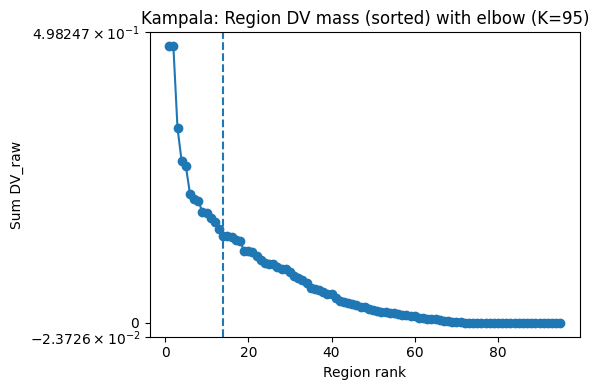

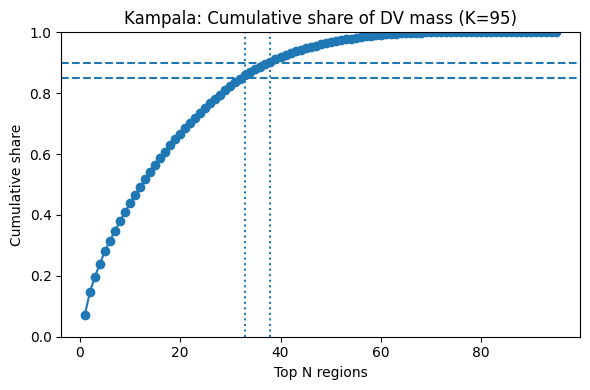

Elbow ≈ Top 14 regions (mass cutoff ≈ 0.148).
Top 33 regions ≈ 85% of DV mass.
Top 38 regions ≈ 90% of DV mass.

Selected region lists (ids):
  elbow: [40, 46, 62, 14, 24, 44, 56, 20, 33, 25, 1, 11, 45, 26] 
  85%  : [40, 46, 62, 14, 24, 44, 56, 20, 33, 25, 1, 11, 45, 26, 65, 52, 16, 30, 2, 68] ...
  90%  : [40, 46, 62, 14, 24, 44, 56, 20, 33, 25, 1, 11, 45, 26, 65, 52, 16, 30, 2, 68] ...


In [ ]:
# ---- ELBOW ON REGION MASS (Kampala, K_REG=95) ----
import numpy as np
import matplotlib.pyplot as plt

CITY = "Kampala"   # titles only
K_REG = 95
USE_LOGY = True     # toggle if the mass curve isn't heavy-tailed
PCT_LINES = (0.85, 0.90)

# Ensure we point to the right region column
REG_COL = globals().get("REG_COL", f"region_k{K_REG}")
if REG_COL not in gdf.columns:
    candidates = [c for c in gdf.columns if c.startswith("region_k")]
    if len(candidates) == 1:
        REG_COL = candidates[0]
    else:
        raise KeyError(f"Region column '{REG_COL}' not found. Candidates: {candidates}")

# Sum DV by region and sort descending
mass = (gdf.groupby(REG_COL)["DV_raw"]
          .sum()
          .sort_values(ascending=False))
vals  = mass.values
ranks = np.arange(1, len(vals) + 1)

if vals.sum() == 0 or len(vals) < 2:
    print("Not enough or zero DV mass to compute an elbow.")
else:
    # Elbow via max distance to line (first -> last)
    p1 = np.array([ranks[0], vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # Cumulative share helpers (e.g., 85% / 90%)
    cumshare = np.cumsum(vals) / vals.sum()
    kP = {int(p*100): int(np.searchsorted(cumshare, p)) + 1 for p in PCT_LINES}

    # 1) Mass (sorted) + elbow
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--')
    if USE_LOGY:
        plt.yscale("symlog")
    plt.title(f"{CITY}: Region DV mass (sorted) with elbow (K={K_REG})")
    plt.xlabel("Region rank")
    plt.ylabel("Sum DV_raw")
    plt.tight_layout()
    plt.show()

    # 2) Cumulative share curve
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p in PCT_LINES:
        plt.axhline(p, linestyle='--')
        plt.axvline(kP[int(p*100)], linestyle=':')
    plt.ylim(0, 1)
    plt.title(f"{CITY}: Cumulative share of DV mass (K={K_REG})")
    plt.xlabel("Top N regions")
    plt.ylabel("Cumulative share")
    plt.tight_layout()
    plt.show()

    # Lists you can pass into the RF step
    top_regions_elbow = mass.index[:elbow_k].tolist()
    top_regions_85    = mass.index[:kP.get(85, 0)].tolist()
    top_regions_90    = mass.index[:kP.get(90, 0)].tolist()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    if 85 in kP: print(f"Top {kP[85]} regions ≈ 85% of DV mass.")
    if 90 in kP: print(f"Top {kP[90]} regions ≈ 90% of DV mass.")
    print("\nSelected region lists (ids):")
    print("  elbow:", top_regions_elbow[:20], "..." if len(top_regions_elbow) > 20 else "")
    print("  85%  :", top_regions_85[:20], "..." if len(top_regions_85) > 20 else "")
    print("  90%  :", top_regions_90[:20], "..." if len(top_regions_90) > 20 else "")

    # Default choice for downstream steps:
    top_regions = top_regions_elbow


In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Kampala"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "uga_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 95              # Kampala: increased region count
TOP_K    = 38              # <-- analyze top-38 regions by DV mass
GLOBAL_SAMPLE_N = 20_000
RANDOM_SEED = 42

RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    parts = []
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        n_pos = min(len(pos), n // 2)
        if n_pos > 0:
            take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
            parts.append(pos.groupby("dv_dec", group_keys=False)
                           .apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    else:
        n_pos = 0
    n_zero = n - n_pos
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all, morans = [], [], []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)
        resid = y[te] - pred
        w = KNN.from_array(coords[te], k=8); w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all); y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(r2=float(r2_score(y_true_all, y_pred_all)),
                   mae=float(mean_absolute_error(y_true_all, y_pred_all)))
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing: print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-38 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PRED_USE].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values

scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PRED_USE, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-38) =========================
region_reports, region_imps = [], []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    if len(sub) < 500:
        continue
    Xr = sub[PRED_USE].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PRED_USE, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-38 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

if not region_imps_df.empty:
    het = (region_imps_df.groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-38 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Kampala] Loaded 375,874 rows | UTM EPSG:32636 | non-zero DV: 185,066
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'uga_general_2020']
Top-38 regions by DV mass: [40, 46, 62, 14, 24, 44, 56, 20, 33, 25] ...

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
                 rwi_interp  0.819995 0.012785
           uga_general_2020  0.650608 0.014149
mean_footprint_area_m2_250m  0.390021 0.007956
        accessibility_index  0.379059 0.006981
               ntl_bilinear  0.302921 0.008901
      spacing_median_m_250m  0.186105 0.003734
           dist_secondary_m  0.157222 0.002644
            dist_tertiary_m  0.130594 0.003582
               slum_mean30m  0.093512 0.001488
  

In [ ]:
import math, warnings
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Kampala"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "uga_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 95              # Kampala: increased region count
TOP_K    = 38              # analyze top-K regions by DV mass
RANDOM_SEED = 42

# Local RF params (only local results requested)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5,
                 random_state=RANDOM_SEED, n_jobs=-1)

# ---------------- MULTI-RUN NEIGHBOURHOOD AREAS (km^2) ----------------
MAX_AREA_LIST_KM2 = [3.0, 2.0, 1.0]
GRID_RES_M   = 30
MIN_PIXELS   = 500

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def perm_importance_table(model, X, y, feature_names, n_repeats=8, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats,
                               random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names,
                       "imp_mean": r.importances_mean,
                       "imp_std":  r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def apply_neighbourhood_cap(sub, max_radius_m, max_pixels,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED,
                            x_col="x_utm", y_col="y_utm"):
    """Cap subset to a circular neighbourhood around its centroid; then apply pixel-count backstop."""
    if sub.empty:
        return None

    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

def run_local_rf_for_area(gdf, pred_use, top_regions, max_area_km2):
    """Run local RFs for a given neighbourhood max area; return per-region report + heterogeneity table."""
    max_radius_m = float(np.sqrt((max_area_km2 * 1e6) / np.pi))
    max_pixels   = int((max_area_km2 * 1e6) / (GRID_RES_M * GRID_RES_M))

    print(f"\n--- Local RF: MAX_AREA_KM2={max_area_km2:.1f} "
          f"(radius≈{max_radius_m:.0f} m, max_pixels≈{max_pixels:,}) ---")

    region_reports, region_imps = [], []

    for rid in top_regions:
        sub0 = gdf[gdf["region"] == rid]
        sub  = apply_neighbourhood_cap(sub0, max_radius_m=max_radius_m, max_pixels=max_pixels)
        if sub is None:
            continue

        Xr = sub[pred_use].values
        yr = sub[DV_COL].values

        scaler_r = StandardScaler().fit(Xr)
        Xr_s = scaler_r.transform(Xr)

        rf_r = RandomForestRegressor(**RF_REGION)
        rf_r.fit(Xr_s, yr)

        imp_r = perm_importance_table(rf_r, Xr_s, yr, pred_use, n_repeats=8, seed=RANDOM_SEED)
        imp_r["region"] = rid
        imp_r["n_used"] = len(sub)
        imp_r["radius_m"] = max_radius_m
        imp_r["max_area_km2"] = max_area_km2
        region_imps.append(imp_r)

        r2 = rf_r.score(Xr_s, yr)  # in-sample diagnostic
        region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

    region_reports_df = pd.DataFrame(region_reports).sort_values("region") if region_reports else pd.DataFrame()
    region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

    if not region_imps_df.empty:
        het = (region_imps_df
               .groupby("feature")["imp_mean"]
               .agg(["mean","std"])
               .rename(columns={"mean":"imp_mean","std":"imp_std"})
               .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0, np.nan))))
        het = het.sort_values("cv", ascending=False).reset_index()
        het["max_area_km2"] = max_area_km2
    else:
        het = pd.DataFrame()

    return region_reports_df, region_imps_df, het

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                       crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# Adapt predictors to what's available
missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing:
    print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= LOCAL RF: RUN FOR 3/2/1 km² =========================
all_region_reports = []
all_heterogeneity = []
all_region_imps = []

for a in MAX_AREA_LIST_KM2:
    rep_df, imps_df, het_df = run_local_rf_for_area(gdf, PRED_USE, top_regions, max_area_km2=a)

    print("\nPer-region diagnostics (r2 is in-sample):")
    print(rep_df.to_string(index=False) if not rep_df.empty else "No regions met size requirement after capping.")

    print("\nImportance heterogeneity (sorted by CV):")
    if not het_df.empty:
        print(het_df[["feature","imp_mean","imp_std","cv","max_area_km2"]].round(3).to_string(index=False))
    else:
        print("(Empty)")

    # store outputs
    if not rep_df.empty:
        rep_df = rep_df.copy()
        rep_df["max_area_km2"] = a
        all_region_reports.append(rep_df)
    if not het_df.empty:
        all_heterogeneity.append(het_df)
    if not imps_df.empty:
        all_region_imps.append(imps_df)

# ========================= OPTIONAL: COMBINED TABLES =========================
combined_region_reports = pd.concat(all_region_reports, ignore_index=True) if all_region_reports else pd.DataFrame()
combined_heterogeneity  = pd.concat(all_heterogeneity, ignore_index=True) if all_heterogeneity else pd.DataFrame()
combined_region_imps    = pd.concat(all_region_imps, ignore_index=True) if all_region_imps else pd.DataFrame()

print("\n\n=== COMBINED HETEROGENEITY (all areas) ===")
if not combined_heterogeneity.empty:
    print(combined_heterogeneity[["max_area_km2","feature","imp_mean","imp_std","cv"]]
          .sort_values(["max_area_km2","cv"], ascending=[False, False])
          .round(3).to_string(index=False))
else:
    print("(Empty)")

# ========================= OPTIONAL: SAVE OUTPUTS =========================
# outdir = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Local_RF_Sensitivity"
# Path(outdir).mkdir(parents=True, exist_ok=True)
# combined_region_reports.to_csv(f"{outdir}/{CITY.lower()}_localrf_region_reports_3_2_1km2.csv", index=False)
# combined_heterogeneity.to_csv(f"{outdir}/{CITY.lower()}_localrf_heterogeneity_3_2_1km2.csv", index=False)
# combined_region_imps.to_csv(f"{outdir}/{CITY.lower()}_localrf_importances_by_region_3_2_1km2.csv", index=False)


[Kampala] Loaded 375,874 rows | UTM EPSG:32636 | non-zero DV: 185,066
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'uga_general_2020']
Top-38 regions by DV mass: [40, 46, 62, 14, 24, 44, 56, 20, 33, 25] ...

--- Local RF: MAX_AREA_KM2=3.0 (radius≈977 m, max_pixels≈3,333) ---

Per-region diagnostics (r2 is in-sample):
 region  n_used       r2
      1    3093 0.998995
      2    1856 0.993301
      4     867 0.995253
      8    1531 0.997158
     10    2003 0.993691
     11    2284 0.999444
     13    1940 0.996374
     14    2047 0.997437
     16    2755 0.998785
     20    2928 0.998472
     24    1763 0.994657
     25    2556 0.997634
     26    2791 0.998729
     30    2746 0.997084
     32    2504 0.998685
     33    2

Kinshasa

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Kinshasa"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 800          # larger city neighborhood target
K_REG      = 95          # more diagnostic regions
ANCHOR_CAP = 800          # max anchors
POOL_MAX   = 200_000      # context-anchor pool
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lonlat(lon, lat):
    """Return EPSG for UTM zone with correct hemisphere."""
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = int(rng.integers(0, n_pts))
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"[{CITY}] Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy() if context_needed > 0 else pd.DataFrame(columns=["x_utm","y_utm"])
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys = []
counts = []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=10, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 120_000:
    nz = nz.sample(120_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 50_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m


Output hidden; open in https://colab.research.google.com to view.

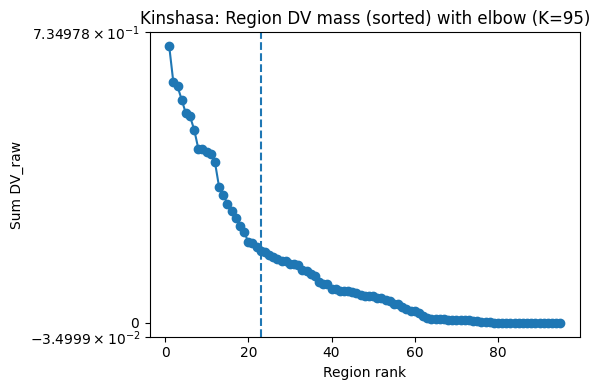

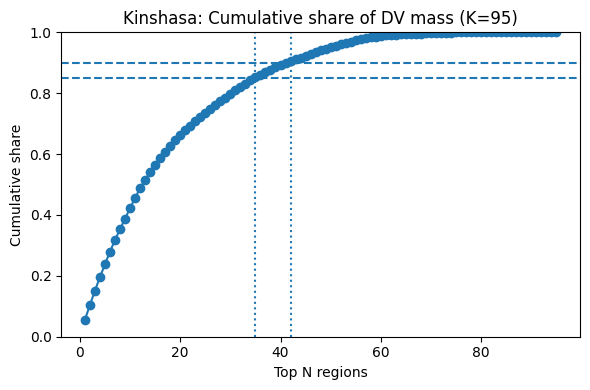

Elbow ≈ Top 23 regions (mass cutoff ≈ 0.181).
Top 35 regions ≈ 85% of DV mass.
Top 42 regions ≈ 90% of DV mass.

Selected region lists (ids):
  elbow: [74, 0, 50, 37, 18, 33, 64, 87, 76, 26, 72, 32, 63, 27, 85, 77, 90, 71, 86, 65] ...
  85%  : [74, 0, 50, 37, 18, 33, 64, 87, 76, 26, 72, 32, 63, 27, 85, 77, 90, 71, 86, 65] ...
  90%  : [74, 0, 50, 37, 18, 33, 64, 87, 76, 26, 72, 32, 63, 27, 85, 77, 90, 71, 86, 65] ...


In [ ]:
# ---- ELBOW ON REGION MASS (Kinshasa, K_REG=95) ----
import numpy as np
import matplotlib.pyplot as plt

CITY   = "Kinshasa"   # titles only
K_REG  = 95
USE_LOGY = True        # toggle if not heavy-tailed
PCT_LINES = (0.85, 0.90)

# Point to the right region column
REG_COL = globals().get("REG_COL", f"region_k{K_REG}")
if REG_COL not in gdf.columns:
    candidates = [c for c in gdf.columns if c.startswith("region_k")]
    if len(candidates) == 1:
        REG_COL = candidates[0]
    else:
        raise KeyError(f"Region column '{REG_COL}' not found. Candidates: {candidates}")

# Sum DV by region and sort descending
mass = (gdf.groupby(REG_COL)["DV_raw"]
          .sum()
          .sort_values(ascending=False))
vals  = mass.values
ranks = np.arange(1, len(vals) + 1)

if vals.sum() == 0 or len(vals) < 2:
    print("Not enough or zero DV mass to compute an elbow.")
else:
    # Elbow via max distance to the line from first to last point
    p1 = np.array([ranks[0],  vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # Cumulative share helpers (e.g., 85% / 90%)
    cumshare = np.cumsum(vals) / vals.sum()
    kP = {int(p*100): int(np.searchsorted(cumshare, p)) + 1 for p in PCT_LINES}

    # 1) Mass (sorted) + elbow
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--')
    if USE_LOGY:
        plt.yscale("symlog")
    plt.title(f"{CITY}: Region DV mass (sorted) with elbow (K={K_REG})")
    plt.xlabel("Region rank")
    plt.ylabel("Sum DV_raw")
    plt.tight_layout()
    plt.show()

    # 2) Cumulative share curve
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p in PCT_LINES:
        plt.axhline(p, linestyle='--')
        plt.axvline(kP[int(p*100)], linestyle=':')
    plt.ylim(0, 1)
    plt.title(f"{CITY}: Cumulative share of DV mass (K={K_REG})")
    plt.xlabel("Top N regions")
    plt.ylabel("Cumulative share")
    plt.tight_layout()
    plt.show()

    # Lists to use downstream
    top_regions_elbow = mass.index[:elbow_k].tolist()
    top_regions_85    = mass.index[:kP.get(85, 0)].tolist()
    top_regions_90    = mass.index[:kP.get(90, 0)].tolist()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    if 85 in kP: print(f"Top {kP[85]} regions ≈ 85% of DV mass.")
    if 90 in kP: print(f"Top {kP[90]} regions ≈ 90% of DV mass.")
    print("\nSelected region lists (ids):")
    print("  elbow:", top_regions_elbow[:20], "..." if len(top_regions_elbow) > 20 else "")
    print("  85%  :", top_regions_85[:20],    "..." if len(top_regions_85) > 20 else "")
    print("  90%  :", top_regions_90[:20],    "..." if len(top_regions_90) > 20 else "")

    # Default choice for downstream steps:
    top_regions = top_regions_elbow


In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Kinshasa"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "cod_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 95              # fixed as requested
TOP_K    = 42              # <-- analyze top-42 regions by DV mass
GLOBAL_SAMPLE_N = 20_000
RANDOM_SEED = 42

RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    parts = []
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        n_pos = min(len(pos), n // 2)
        if n_pos > 0:
            take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
            parts.append(pos.groupby("dv_dec", group_keys=False)
                           .apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    else:
        n_pos = 0
    n_zero = n - n_pos
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all, morans = [], [], []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)
        resid = y[te] - pred
        w = KNN.from_array(coords[te], k=8); w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all); y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(r2=float(r2_score(y_true_all, y_pred_all)),
                   mae=float(mean_absolute_error(y_true_all, y_pred_all)))
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing: print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-42 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PRED_USE].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values

scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PRED_USE, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-42) =========================
region_reports, region_imps = [], []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    if len(sub) < 500:
        continue
    Xr = sub[PRED_USE].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PRED_USE, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-42 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

if not region_imps_df.empty:
    het = (region_imps_df.groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-42 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Kinshasa] Loaded 293,871 rows | UTM EPSG:32733 | non-zero DV: 162,439
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'cod_general_2020']
Top-42 regions by DV mass: [74, 0, 50, 37, 18, 33, 64, 87, 76, 26] ...

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
                 rwi_interp  0.893758 0.011787
           cod_general_2020  0.761607 0.012017
           dist_secondary_m  0.442937 0.006364
        accessibility_index  0.328865 0.005257
               ntl_bilinear  0.297082 0.008108
mean_footprint_area_m2_250m  0.289677 0.008599
               u18_bilinear  0.189154 0.010514
            dist_tertiary_m  0.135997 0.002871
    built_environment_index  0.073529 0.001816
  

In [ ]:
import math, warnings
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Kinshasa"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "cod_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 95              # fixed as requested
TOP_K    = 42              # analyze top-K regions by DV mass
RANDOM_SEED = 42

# Local RF params (only local results requested)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5,
                 random_state=RANDOM_SEED, n_jobs=-1)

# ---------------- MULTI-RUN NEIGHBOURHOOD AREAS (km^2) ----------------
MAX_AREA_LIST_KM2 = [3.0, 2.0, 1.0]
GRID_RES_M   = 30
MIN_PIXELS   = 500

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def perm_importance_table(model, X, y, feature_names, n_repeats=8, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats,
                               random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names,
                       "imp_mean": r.importances_mean,
                       "imp_std":  r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def apply_neighbourhood_cap(sub, max_radius_m, max_pixels,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED,
                            x_col="x_utm", y_col="y_utm"):
    """Cap subset to a circular neighbourhood around its centroid; then apply pixel-count backstop."""
    if sub.empty:
        return None

    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

def run_local_rf_for_area(gdf, pred_use, top_regions, max_area_km2):
    """Run local RFs for a given neighbourhood max area; return per-region report + heterogeneity table."""
    max_radius_m = float(np.sqrt((max_area_km2 * 1e6) / np.pi))
    max_pixels   = int((max_area_km2 * 1e6) / (GRID_RES_M * GRID_RES_M))

    print(f"\n--- Local RF: MAX_AREA_KM2={max_area_km2:.1f} "
          f"(radius≈{max_radius_m:.0f} m, max_pixels≈{max_pixels:,}) ---")

    region_reports, region_imps = [], []

    for rid in top_regions:
        sub0 = gdf[gdf["region"] == rid]
        sub  = apply_neighbourhood_cap(sub0, max_radius_m=max_radius_m, max_pixels=max_pixels)
        if sub is None:
            continue

        Xr = sub[pred_use].values
        yr = sub[DV_COL].values

        scaler_r = StandardScaler().fit(Xr)
        Xr_s = scaler_r.transform(Xr)

        rf_r = RandomForestRegressor(**RF_REGION)
        rf_r.fit(Xr_s, yr)

        imp_r = perm_importance_table(rf_r, Xr_s, yr, pred_use, n_repeats=8, seed=RANDOM_SEED)
        imp_r["region"] = rid
        imp_r["n_used"] = len(sub)
        imp_r["radius_m"] = max_radius_m
        imp_r["max_area_km2"] = max_area_km2
        region_imps.append(imp_r)

        r2 = rf_r.score(Xr_s, yr)  # in-sample diagnostic
        region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

    region_reports_df = pd.DataFrame(region_reports).sort_values("region") if region_reports else pd.DataFrame()
    region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

    if not region_imps_df.empty:
        het = (region_imps_df
               .groupby("feature")["imp_mean"]
               .agg(["mean","std"])
               .rename(columns={"mean":"imp_mean","std":"imp_std"})
               .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0, np.nan))))
        het = het.sort_values("cv", ascending=False).reset_index()
        het["max_area_km2"] = max_area_km2
    else:
        het = pd.DataFrame()

    return region_reports_df, region_imps_df, het

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                       crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# Adapt predictors to what's available
missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing:
    print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= LOCAL RF: RUN FOR 3/2/1 km² =========================
all_region_reports = []
all_heterogeneity = []
all_region_imps = []

for a in MAX_AREA_LIST_KM2:
    rep_df, imps_df, het_df = run_local_rf_for_area(gdf, PRED_USE, top_regions, max_area_km2=a)

    print("\nPer-region diagnostics (r2 is in-sample):")
    print(rep_df.to_string(index=False) if not rep_df.empty else "No regions met size requirement after capping.")

    print("\nImportance heterogeneity (sorted by CV):")
    if not het_df.empty:
        print(het_df[["feature","imp_mean","imp_std","cv","max_area_km2"]].round(3).to_string(index=False))
    else:
        print("(Empty)")

    # store outputs
    if not rep_df.empty:
        rep_df = rep_df.copy()
        rep_df["max_area_km2"] = a
        all_region_reports.append(rep_df)
    if not het_df.empty:
        all_heterogeneity.append(het_df)
    if not imps_df.empty:
        all_region_imps.append(imps_df)

# ========================= OPTIONAL: COMBINED TABLES =========================
combined_region_reports = pd.concat(all_region_reports, ignore_index=True) if all_region_reports else pd.DataFrame()
combined_heterogeneity  = pd.concat(all_heterogeneity, ignore_index=True) if all_heterogeneity else pd.DataFrame()
combined_region_imps    = pd.concat(all_region_imps, ignore_index=True) if all_region_imps else pd.DataFrame()

print("\n\n=== COMBINED HETEROGENEITY (all areas) ===")
if not combined_heterogeneity.empty:
    print(combined_heterogeneity[["max_area_km2","feature","imp_mean","imp_std","cv"]]
          .sort_values(["max_area_km2","cv"], ascending=[False, False])
          .round(3).to_string(index=False))
else:
    print("(Empty)")

# ========================= OPTIONAL: SAVE OUTPUTS =========================
# outdir = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Local_RF_Sensitivity"
# Path(outdir).mkdir(parents=True, exist_ok=True)
# combined_region_reports.to_csv(f"{outdir}/{CITY.lower()}_localrf_region_reports_3_2_1km2.csv", index=False)
# combined_heterogeneity.to_csv(f"{outdir}/{CITY.lower()}_localrf_heterogeneity_3_2_1km2.csv", index=False)
# combined_region_imps.to_csv(f"{outdir}/{CITY.lower()}_localrf_importances_by_region_3_2_1km2.csv", index=False)


[Kinshasa] Loaded 293,871 rows | UTM EPSG:32733 | non-zero DV: 162,439
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'cod_general_2020']
Top-42 regions by DV mass: [74, 0, 50, 37, 18, 33, 64, 87, 76, 26] ...

--- Local RF: MAX_AREA_KM2=3.0 (radius≈977 m, max_pixels≈3,333) ---

Per-region diagnostics (r2 is in-sample):
 region  n_used       r2
      0    3057 0.999237
      8    2940 0.998574
     12    2908 0.995303
     13    1973 0.997907
     16    2857 0.998859
     18    3045 0.999016
     20    2822 0.999054
     25    2712 0.997699
     26    2651 0.999021
     27    3063 0.998390
     29    2724 0.998454
     32    3051 0.997801
     33    3120 0.999183
     35    2646 0.999138
     37    3017 0.999334
     38    2

Lagos

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Lagos"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 800          # larger city neighborhood target
K_REG      = 95           # number of diagnostic regions (fixed moving forward)
ANCHOR_CAP = 800          # max anchors
POOL_MAX   = 200_000      # context-anchor pool
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lonlat(lon, lat):
    """Return EPSG for UTM zone with correct hemisphere."""
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = int(rng.integers(0, n_pts))
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"[{CITY}] Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy() if context_needed > 0 else pd.DataFrame(columns=["x_utm","y_utm"])
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys = []
counts = []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=10, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 120_000:
    nz = nz.sample(120_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=14, blur=16, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 50_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m


Output hidden; open in https://colab.research.google.com to view.

Chosen UTM: EPSG:32631
Site anchors (thinned @ 250 m): 497
Anchor plan: N≈200,000, T=800, A=250 (cap 800)
Total anchors: 497 | site=497 context=0
Saved: /content/drive/MyDrive/Miscellaneous/Lagos_figureA_exposure_anchors.png


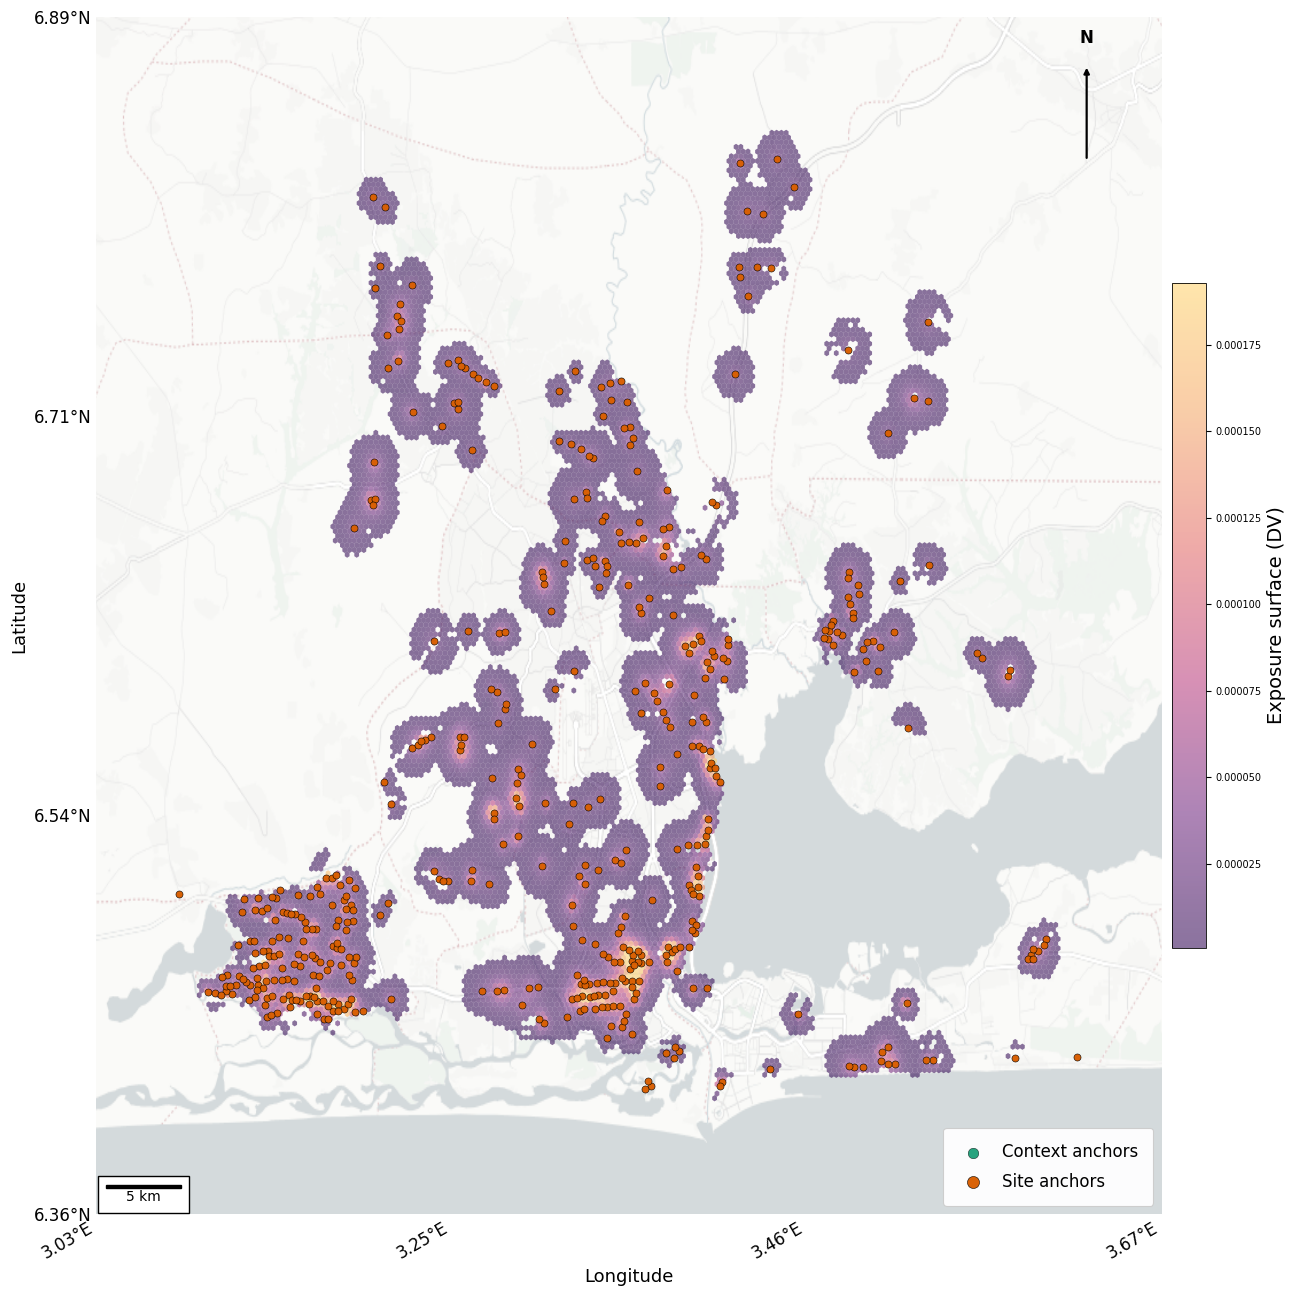

Saved: /content/drive/MyDrive/Miscellaneous/Lagos_figureB_exposure_anchors_kmeans.png


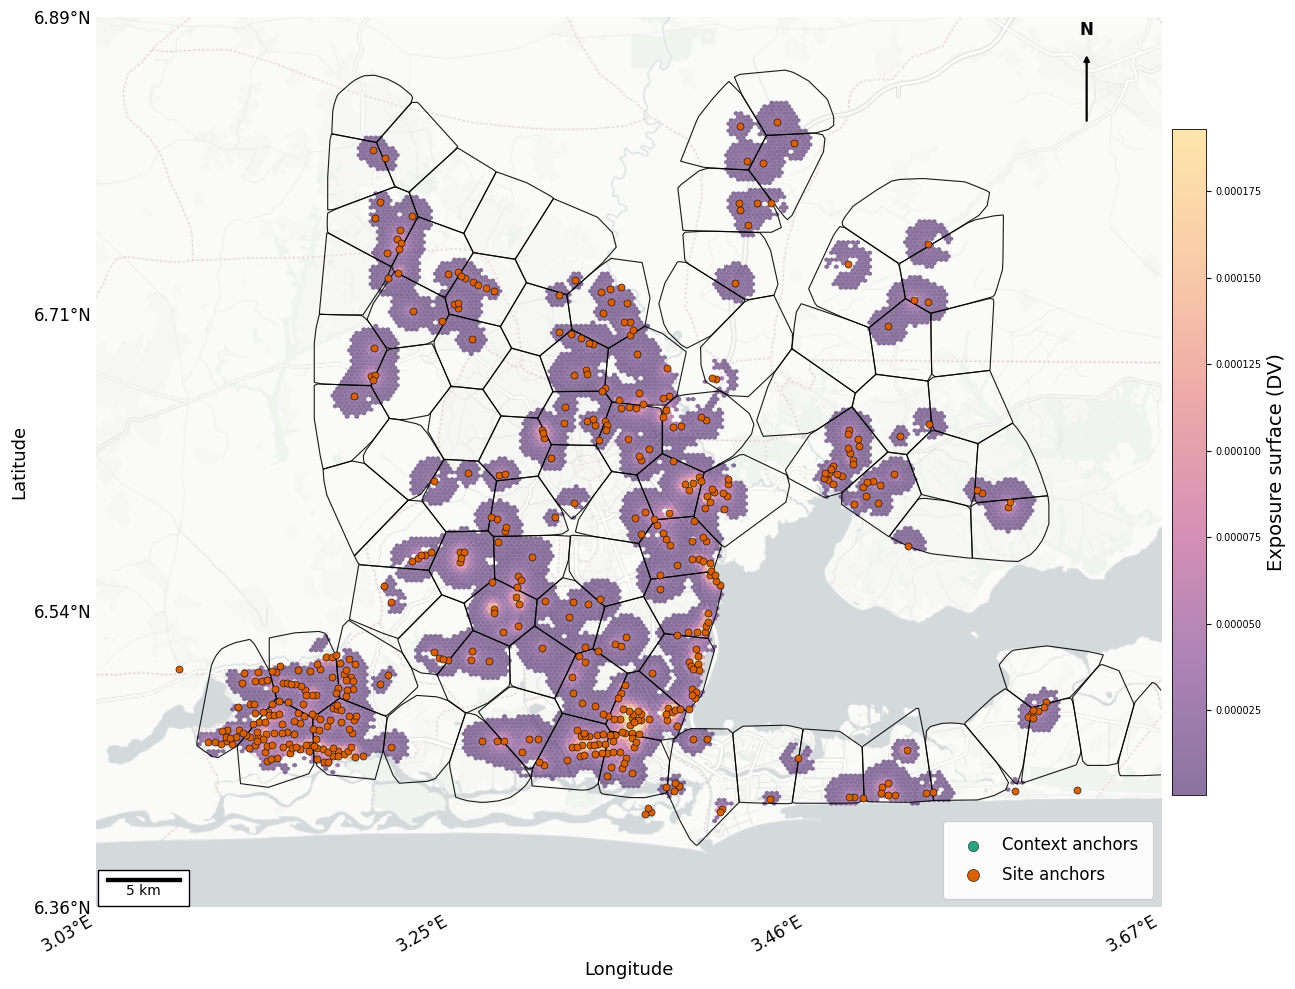

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint
import matplotlib.pyplot as plt
import contextily as ctx
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
from pyproj import CRS, Transformer

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Lagos"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL = "DV_log1p"
H = 250.0
T_TARGET = 800
K_REG = 95
ANCHOR_CAP = 800
POOL_MAX = 200_000

# Figure size (match your final aesthetic)
DPI = 300
FIGSIZE = (13, 13)

# Exposure colormap (same as your figures)
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "exposure_plasma_soft",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# ---------------- CRS ----------------
CRS_WEBMERC = CRS.from_epsg(3857)
CRS_WGS84   = CRS.from_epsg(4326)

# ---------------- HELPERS ----------------
def utm_epsg_for_lonlat(lon, lat):
    """Return EPSG for UTM zone with correct hemisphere."""
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone if lat >= 0 else 32700 + zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = int(rng.integers(0, n_pts))
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

def format_lon(lon):
    hemi = "E" if lon >= 0 else "W"
    return f"{abs(lon):.2f}°{hemi}"

def format_lat(lat):
    hemi = "N" if lat >= 0 else "S"
    return f"{abs(lat):.2f}°{hemi}"

def add_latlon_ticks(ax):
    """Convert current EPSG:3857 axes to lat/lon tick labels."""
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    transformer = Transformer.from_crs(CRS_WEBMERC, CRS_WGS84, always_xy=True)

    x_ticks = np.linspace(x_min, x_max, 4)
    y_ticks = np.linspace(y_min, y_max, 4)

    y_c = (y_min + y_max) / 2.0
    x_c = (x_min + x_max) / 2.0

    lons = [transformer.transform(x, y_c)[0] for x in x_ticks]
    lats = [transformer.transform(x_c, y)[1] for y in y_ticks]

    ax.set_xticks(x_ticks)
    ax.set_xticklabels([format_lon(lo) for lo in lons], fontsize=12)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels([format_lat(la) for la in lats], fontsize=12)

    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

def add_north_arrow(ax, x=0.92, y=0.90, size=0.08, text="N"):
    ax.annotate(
        "", xy=(x, y + size), xytext=(x, y),
        xycoords=ax.transAxes, textcoords=ax.transAxes,
        arrowprops=dict(arrowstyle="-|>", lw=1.6, color="black"),
        zorder=60
    )
    ax.text(
        x, y + size + 0.015, text,
        transform=ax.transAxes, ha="center", va="bottom",
        fontsize=12, fontweight="bold", color="black", zorder=61
    )

def add_scale_bar(ax, length_m=5000, location="lower left", pad=0.6):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(
        ax.transData,
        length_m,
        f"{int(length_m/1000)} km" if length_m >= 1000 else f"{int(length_m)} m",
        location,
        pad=pad,
        color="black",
        frameon=True,
        size_vertical=length_m * 0.03,
        fontproperties=fontprops
    )
    ax.add_artist(scalebar)

def _prep_plot_data(gdf_utm, anchors_df):
    """Project to EPSG:3857, clip weights, thin points, compute extent."""
    gdf_3857 = gdf_utm.to_crs(3857)

    anchors_3857 = gpd.GeoDataFrame(
        anchors_df,
        geometry=gpd.points_from_xy(anchors_df["x_utm"], anchors_df["y_utm"]),
        crs=gdf_utm.crs
    ).to_crs(3857)

    gdf_3857["DV_w"] = gdf_3857["DV_raw"].astype(float)
    nz = gdf_3857[gdf_3857["DV_w"] > 0].copy()
    if len(nz) == 0:
        nz = gdf_3857.copy()

    q99 = nz["DV_w"].quantile(0.99) if len(nz) else 1.0
    nz["DV_w"] = nz["DV_w"].clip(upper=q99)

    MAX_PTS = 120_000
    if len(nz) > MAX_PTS:
        nz = nz.sample(MAX_PTS, random_state=42)

    minx, miny, maxx, maxy = nz.total_bounds
    pad_x = (maxx - minx) * 0.12
    pad_y = (maxy - miny) * 0.12
    xlim = (minx - pad_x, maxx + pad_x)
    ylim = (miny - pad_y, maxy + pad_y)

    return nz, anchors_3857, xlim, ylim

def plot_exposure_anchors(gdf_utm, anchors_df):
    """Figure A: exposure + anchors"""
    nz, anchors_3857, xlim, ylim = _prep_plot_data(gdf_utm, anchors_df)

    fig, ax = plt.subplots(figsize=FIGSIZE)

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    ctx.add_basemap(
        ax,
        source=ctx.providers.CartoDB.PositronNoLabels,
        attribution=False,
        zorder=0
    )

    hb = ax.hexbin(
        nz.geometry.x.values,
        nz.geometry.y.values,
        C=nz["DV_w"].values,
        reduce_C_function=np.mean,
        gridsize=180,
        mincnt=1,
        linewidths=0,
        alpha=0.55,
        cmap=exposure_cmap,
        zorder=5
    )

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    is_site = anchors_3857["anchor_type"].astype(str).eq("site")
    ax.scatter(
        anchors_3857.loc[~is_site, "geometry"].x,
        anchors_3857.loc[~is_site, "geometry"].y,
        s=20, marker="o",
        edgecolor="black", linewidth=0.3,
        facecolor="#1b9e77",
        alpha=0.95,
        zorder=20,
        label="Context anchors"
    )
    ax.scatter(
        anchors_3857.loc[is_site, "geometry"].x,
        anchors_3857.loc[is_site, "geometry"].y,
        s=26, marker="o",
        edgecolor="black", linewidth=0.4,
        facecolor="#d95f02",
        alpha=0.98,
        zorder=21,
        label="Site anchors"
    )

    add_north_arrow(ax, x=0.93, y=0.88, size=0.08)
    add_scale_bar(ax, length_m=5000, location="lower left")

    add_latlon_ticks(ax)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    leg = ax.legend(
        loc="lower right",
        frameon=True,
        fontsize=12,
        markerscale=1.7,
        handlelength=1.8,
        labelspacing=0.7,
        borderpad=0.9
    )
    leg.get_frame().set_linewidth(0.8)
    leg.get_frame().set_alpha(0.95)

    plt.tight_layout()

    outpath = os.path.join(OUT_DIR, f"{CITY}_figureA_exposure_anchors.png")
    fig.savefig(outpath, dpi=DPI, bbox_inches="tight", facecolor="white")
    print("Saved:", outpath)

    plt.show()

def plot_exposure_anchors_kmeans(gdf_utm, anchors_df):
    """Figure B: exposure + anchors + k-means convex hull region outlines (black)"""
    # K-means regions on UTM coordinates
    REG_COL = f"region_k{K_REG}"
    km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
    gdf_utm = gdf_utm.copy()
    gdf_utm[REG_COL] = km.fit_predict(gdf_utm[["x_utm", "y_utm"]].values)

    polys = []
    for rid in sorted(gdf_utm[REG_COL].unique()):
        sub = gdf_utm.loc[gdf_utm[REG_COL] == rid, ["x_utm", "y_utm"]].values
        if len(sub) >= 3:
            polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
    regions_utm = gpd.GeoDataFrame(polys, crs=gdf_utm.crs)

    # Prep plot data
    nz, anchors_3857, xlim, ylim = _prep_plot_data(gdf_utm, anchors_df)
    regions_3857 = regions_utm.to_crs(3857)

    fig, ax = plt.subplots(figsize=FIGSIZE)

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    ctx.add_basemap(
        ax,
        source=ctx.providers.CartoDB.PositronNoLabels,
        attribution=False,
        zorder=0
    )

    hb = ax.hexbin(
        nz.geometry.x.values,
        nz.geometry.y.values,
        C=nz["DV_w"].values,
        reduce_C_function=np.mean,
        gridsize=180,
        mincnt=1,
        linewidths=0,
        alpha=0.55,
        cmap=exposure_cmap,
        zorder=5
    )
    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    # Black k-means hull outlines
    regions_3857.boundary.plot(
        ax=ax,
        color="black",
        linewidth=0.8,
        alpha=0.9,
        zorder=12,
        aspect="auto"
    )

    is_site = anchors_3857["anchor_type"].astype(str).eq("site")
    ax.scatter(
        anchors_3857.loc[~is_site, "geometry"].x,
        anchors_3857.loc[~is_site, "geometry"].y,
        s=20, marker="o",
        edgecolor="black", linewidth=0.3,
        facecolor="#1b9e77",
        alpha=0.95,
        zorder=20,
        label="Context anchors"
    )
    ax.scatter(
        anchors_3857.loc[is_site, "geometry"].x,
        anchors_3857.loc[is_site, "geometry"].y,
        s=26, marker="o",
        edgecolor="black", linewidth=0.4,
        facecolor="#d95f02",
        alpha=0.98,
        zorder=21,
        label="Site anchors"
    )

    add_north_arrow(ax, x=0.93, y=0.88, size=0.08)
    add_scale_bar(ax, length_m=5000, location="lower left")

    add_latlon_ticks(ax)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    leg = ax.legend(
        loc="lower right",
        frameon=True,
        fontsize=12,
        markerscale=1.7,
        handlelength=1.8,
        labelspacing=0.7,
        borderpad=0.9
    )
    leg.get_frame().set_linewidth(0.8)
    leg.get_frame().set_alpha(0.95)

    plt.tight_layout()

    outpath = os.path.join(OUT_DIR, f"{CITY}_figureB_exposure_anchors_kmeans.png")
    fig.savefig(outpath, dpi=DPI, bbox_inches="tight", facecolor="white")
    print("Saved:", outpath)

    plt.show()

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude", "latitude", DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs="EPSG:4326"
).to_crs(epsg)

gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL].astype(float))

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid

    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)

    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"Site anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("Site layer not found/loaded; continuing with context anchors only.", e)

rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"Anchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)

context_anchors = (
    pool.iloc[sel_idx][["x_utm", "y_utm"]].copy()
    if context_needed > 0 else
    pd.DataFrame(columns=["x_utm", "y_utm"])
)
context_anchors["anchor_type"] = "context"

if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(
            x_utm=site_anchors.geometry.x,
            y_utm=site_anchors.geometry.y
        )[["x_utm", "y_utm", "anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors: {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- PLOTS ----------------
plot_exposure_anchors(gdf, anchors)          # Figure A
plot_exposure_anchors_kmeans(gdf, anchors)   # Figure B


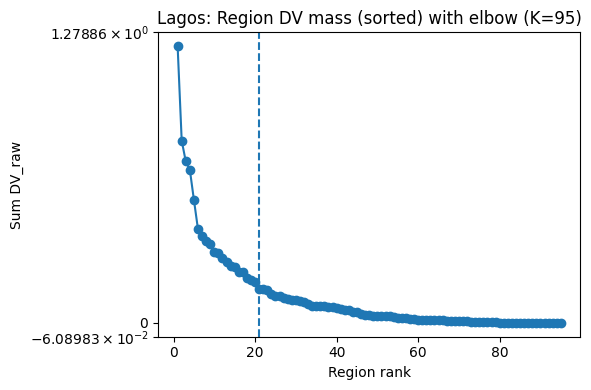

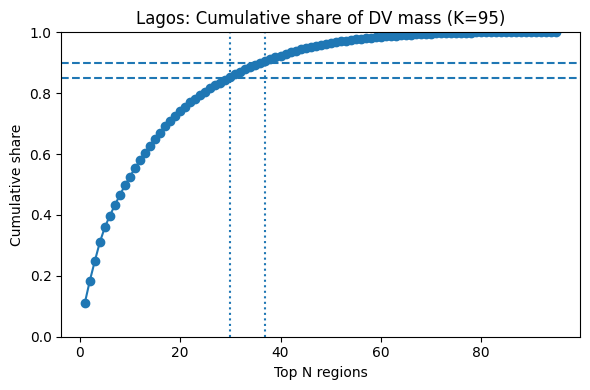

Elbow ≈ Top 21 regions (mass cutoff ≈ 0.148).
Top 30 regions ≈ 85% of DV mass.
Top 37 regions ≈ 90% of DV mass.

Selected region lists (ids):
  elbow: [0, 42, 86, 43, 69, 82, 76, 54, 94, 83, 39, 18, 20, 24, 36, 4, 74, 80, 79, 11] ...
  85%  : [0, 42, 86, 43, 69, 82, 76, 54, 94, 83, 39, 18, 20, 24, 36, 4, 74, 80, 79, 11] ...
  90%  : [0, 42, 86, 43, 69, 82, 76, 54, 94, 83, 39, 18, 20, 24, 36, 4, 74, 80, 79, 11] ...


In [ ]:
# ---- ELBOW ON REGION MASS (Lagos, K_REG=95) ----
import numpy as np
import matplotlib.pyplot as plt

CITY   = "Lagos"    # titles only
K_REG  = 95
USE_LOGY = True      # toggle off if not heavy-tailed
PCT_LINES = (0.85, 0.90)

# Point to the right region column
REG_COL = globals().get("REG_COL", f"region_k{K_REG}")
if REG_COL not in gdf.columns:
    candidates = [c for c in gdf.columns if c.startswith("region_k")]
    if len(candidates) == 1:
        REG_COL = candidates[0]
    else:
        raise KeyError(f"Region column '{REG_COL}' not found. Candidates: {candidates}")

# Sum DV by region and sort descending
mass = (gdf.groupby(REG_COL)["DV_raw"]
          .sum()
          .sort_values(ascending=False))
vals  = mass.values
ranks = np.arange(1, len(vals) + 1)

if vals.sum() == 0 or len(vals) < 2:
    print("Not enough or zero DV mass to compute an elbow.")
else:
    # Elbow via max distance to the line from first to last point
    p1 = np.array([ranks[0],  vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # Cumulative share helpers (e.g., 85% / 90%)
    cumshare = np.cumsum(vals) / vals.sum()
    kP = {int(p*100): int(np.searchsorted(cumshare, p)) + 1 for p in PCT_LINES}

    # 1) Mass (sorted) + elbow
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--')
    if USE_LOGY:
        plt.yscale("symlog")
    plt.title(f"{CITY}: Region DV mass (sorted) with elbow (K={K_REG})")
    plt.xlabel("Region rank")
    plt.ylabel("Sum DV_raw")
    plt.tight_layout()
    plt.show()

    # 2) Cumulative share curve
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p in PCT_LINES:
        plt.axhline(p, linestyle='--')
        plt.axvline(kP[int(p*100)], linestyle=':')
    plt.ylim(0, 1)
    plt.title(f"{CITY}: Cumulative share of DV mass (K={K_REG})")
    plt.xlabel("Top N regions")
    plt.ylabel("Cumulative share")
    plt.tight_layout()
    plt.show()

    # Lists to use downstream
    top_regions_elbow = mass.index[:elbow_k].tolist()
    top_regions_85    = mass.index[:kP.get(85, 0)].tolist()
    top_regions_90    = mass.index[:kP.get(90, 0)].tolist()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    if 85 in kP: print(f"Top {kP[85]} regions ≈ 85% of DV mass.")
    if 90 in kP: print(f"Top {kP[90]} regions ≈ 90% of DV mass.")
    print("\nSelected region lists (ids):")
    print("  elbow:", top_regions_elbow[:20], "..." if len(top_regions_elbow) > 20 else "")
    print("  85%  :", top_regions_85[:20],    "..." if len(top_regions_85) > 20 else "")
    print("  90%  :", top_regions_90[:20],    "..." if len(top_regions_90) > 20 else "")

    # Default choice for downstream steps:
    top_regions = top_regions_elbow


In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Lagos"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "nga_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 95               # fixed moving forward
TOP_K    = 25 #37               # <-- analyze top-37 regions by DV mass
GLOBAL_SAMPLE_N = 20_000
RANDOM_SEED = 42

RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    parts = []
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        n_pos = min(len(pos), n // 2)
        if n_pos > 0:
            take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
            parts.append(pos.groupby("dv_dec", group_keys=False)
                           .apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    else:
        n_pos = 0
    n_zero = n - n_pos
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all, morans = [], [], []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)
        resid = y[te] - pred
        w = KNN.from_array(coords[te], k=8); w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all); y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(r2=float(r2_score(y_true_all, y_pred_all)),
                   mae=float(mean_absolute_error(y_true_all, y_pred_all)))
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing: print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-37 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PRED_USE].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values

scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PRED_USE, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(14).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-37) =========================
region_reports, region_imps = [], []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    if len(sub) < 500:
        continue
    Xr = sub[PRED_USE].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PRED_USE, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-37 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

if not region_imps_df.empty:
    het = (region_imps_df.groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-37 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Lagos] Loaded 1,243,725 rows | UTM EPSG:32631 | non-zero DV: 487,035
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'nga_general_2020']
Top-25 regions by DV mass: [0, 42, 86, 43, 69, 82, 76, 54, 94, 83] ...

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
           nga_general_2020  1.249101 0.027435
        accessibility_index  0.482084 0.010574
               ntl_bilinear  0.377168 0.009425
                 rwi_interp  0.223799 0.006532
mean_footprint_area_m2_250m  0.192109 0.004822
           dist_secondary_m  0.163832 0.004050
               u18_bilinear  0.137787 0.010821
            dist_tertiary_m  0.135340 0.003119
      spacing_median_m_250m  0.111939 0.004461
   

In [ ]:
import math, warnings
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Lagos"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "nga_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 95               # fixed moving forward
TOP_K    = 37               # analyze top-K regions by DV mass
RANDOM_SEED = 42

# Local RF params (only local results requested)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5,
                 random_state=RANDOM_SEED, n_jobs=-1)

# ---------------- MULTI-RUN NEIGHBOURHOOD AREAS (km^2) ----------------
MAX_AREA_LIST_KM2 = [3.0, 2.0, 1.0]
GRID_RES_M   = 30
MIN_PIXELS   = 500

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def perm_importance_table(model, X, y, feature_names, n_repeats=8, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats,
                               random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names,
                       "imp_mean": r.importances_mean,
                       "imp_std":  r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def apply_neighbourhood_cap(sub, max_radius_m, max_pixels,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED,
                            x_col="x_utm", y_col="y_utm"):
    """Cap subset to a circular neighbourhood around its centroid; then apply pixel-count backstop."""
    if sub.empty:
        return None

    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

def run_local_rf_for_area(gdf, pred_use, top_regions, max_area_km2):
    """Run local RFs for a given neighbourhood max area; return per-region report + heterogeneity table."""
    max_radius_m = float(np.sqrt((max_area_km2 * 1e6) / np.pi))
    max_pixels   = int((max_area_km2 * 1e6) / (GRID_RES_M * GRID_RES_M))

    print(f"\n--- Local RF: MAX_AREA_KM2={max_area_km2:.1f} "
          f"(radius≈{max_radius_m:.0f} m, max_pixels≈{max_pixels:,}) ---")

    region_reports, region_imps = [], []

    for rid in top_regions:
        sub0 = gdf[gdf["region"] == rid]
        sub  = apply_neighbourhood_cap(sub0, max_radius_m=max_radius_m, max_pixels=max_pixels)
        if sub is None:
            continue

        Xr = sub[pred_use].values
        yr = sub[DV_COL].values

        scaler_r = StandardScaler().fit(Xr)
        Xr_s = scaler_r.transform(Xr)

        rf_r = RandomForestRegressor(**RF_REGION)
        rf_r.fit(Xr_s, yr)

        imp_r = perm_importance_table(rf_r, Xr_s, yr, pred_use, n_repeats=8, seed=RANDOM_SEED)
        imp_r["region"] = rid
        imp_r["n_used"] = len(sub)
        imp_r["radius_m"] = max_radius_m
        imp_r["max_area_km2"] = max_area_km2
        region_imps.append(imp_r)

        r2 = rf_r.score(Xr_s, yr)  # in-sample diagnostic
        region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

    region_reports_df = pd.DataFrame(region_reports).sort_values("region") if region_reports else pd.DataFrame()
    region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

    if not region_imps_df.empty:
        het = (region_imps_df
               .groupby("feature")["imp_mean"]
               .agg(["mean","std"])
               .rename(columns={"mean":"imp_mean","std":"imp_std"})
               .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0, np.nan))))
        het = het.sort_values("cv", ascending=False).reset_index()
        het["max_area_km2"] = max_area_km2
    else:
        het = pd.DataFrame()

    return region_reports_df, region_imps_df, het

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                       crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# Adapt predictors to what's available
missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing:
    print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= LOCAL RF: RUN FOR 3/2/1 km² =========================
all_region_reports = []
all_heterogeneity = []
all_region_imps = []

for a in MAX_AREA_LIST_KM2:
    rep_df, imps_df, het_df = run_local_rf_for_area(gdf, PRED_USE, top_regions, max_area_km2=a)

    print("\nPer-region diagnostics (r2 is in-sample):")
    print(rep_df.to_string(index=False) if not rep_df.empty else "No regions met size requirement after capping.")

    print("\nImportance heterogeneity (sorted by CV):")
    if not het_df.empty:
        print(het_df[["feature","imp_mean","imp_std","cv","max_area_km2"]].round(3).to_string(index=False))
    else:
        print("(Empty)")

    # store outputs
    if not rep_df.empty:
        rep_df = rep_df.copy()
        rep_df["max_area_km2"] = a
        all_region_reports.append(rep_df)
    if not het_df.empty:
        all_heterogeneity.append(het_df)
    if not imps_df.empty:
        all_region_imps.append(imps_df)

# ========================= OPTIONAL: COMBINED TABLES =========================
combined_region_reports = pd.concat(all_region_reports, ignore_index=True) if all_region_reports else pd.DataFrame()
combined_heterogeneity  = pd.concat(all_heterogeneity, ignore_index=True) if all_heterogeneity else pd.DataFrame()
combined_region_imps    = pd.concat(all_region_imps, ignore_index=True) if all_region_imps else pd.DataFrame()

print("\n\n=== COMBINED HETEROGENEITY (all areas) ===")
if not combined_heterogeneity.empty:
    print(combined_heterogeneity[["max_area_km2","feature","imp_mean","imp_std","cv"]]
          .sort_values(["max_area_km2","cv"], ascending=[False, False])
          .round(3).to_string(index=False))
else:
    print("(Empty)")

# ========================= OPTIONAL: SAVE OUTPUTS =========================
# outdir = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Local_RF_Sensitivity"
# Path(outdir).mkdir(parents=True, exist_ok=True)
# combined_region_reports.to_csv(f"{outdir}/{CITY.lower()}_localrf_region_reports_3_2_1km2.csv", index=False)
# combined_heterogeneity.to_csv(f"{outdir}/{CITY.lower()}_localrf_heterogeneity_3_2_1km2.csv", index=False)
# combined_region_imps.to_csv(f"{outdir}/{CITY.lower()}_localrf_importances_by_region_3_2_1km2.csv", index=False)


[Lagos] Loaded 1,243,725 rows | UTM EPSG:32631 | non-zero DV: 487,035
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'nga_general_2020']
Top-37 regions by DV mass: [0, 42, 86, 43, 69, 82, 76, 54, 94, 83] ...

--- Local RF: MAX_AREA_KM2=3.0 (radius≈977 m, max_pixels≈3,333) ---

Per-region diagnostics (r2 is in-sample):
 region  n_used       r2
      0    2194 0.999517
      4    3000 0.999417
      8    2999 0.998312
     11    3014 0.997875
     15    3138 0.993964
     17    2946 0.994157
     18    2614 0.998827
     20    1174 0.994396
     24    2790 0.996462
     28    2974 0.998968
     30    2873 0.998663
     32    2768 0.999168
     34    2967 0.999242
     35    2457 0.992509
     36    3084 0.996142
     38    23

Maputo

In [ ]:
import math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
from folium.plugins import HeatMap
from sklearn.cluster import KMeans
from shapely.geometry import MultiPoint

warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
CITY = "Maputo"
BASE = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets"
CSV = f"{BASE}/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITE_SHP = f"/content/drive/MyDrive/Results_2/Imagery_2024/Mapped_sites/Final_mapped/{CITY}/{CITY}_sites.shp"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","pct_low_child_component","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m"
]
DV_COL     = "DV_log1p"   # model target (log1p)
H          = 250.0        # PN half-life (m)
T_TARGET   = 800          # smaller-city neighborhood target
K_REG      = 65           # keep consistent; drop to ~80–90 if too granular
ANCHOR_CAP = 100          # lower cap for smaller city
POOL_MAX   = 120_000      # smaller context pool
PALETTE    = ["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]

# ---------------- HELPERS ----------------
def utm_epsg_for_lonlat(lon, lat):
    """Return EPSG for UTM zone with correct hemisphere."""
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def farthest_point_sampling(xy, n, seed=42):
    if n <= 0 or xy.shape[0] == 0:
        return np.array([], dtype=int)
    rng = np.random.default_rng(seed)
    n_pts = xy.shape[0]
    start = int(rng.integers(0, n_pts))
    sel = [start]
    dist = np.sum((xy - xy[start])**2, axis=1)
    for _ in range(1, min(n, n_pts)):
        i = int(np.argmax(dist))
        sel.append(i)
        dist = np.minimum(dist, np.sum((xy - xy[i])**2, axis=1))
    return np.array(sel, dtype=int)

# ---------------- LOAD & PROJECT ----------------
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must have longitude, latitude, and DV_log1p."

missing = [c for c in PREDICTORS if c not in df.columns]
present = [c for c in PREDICTORS if c in df.columns]
print(f"[{CITY}] Loaded: {len(df):,} rows, {df.shape[1]} cols")
print(f"Predictors present ({len(present)}): {present}")
print(f"Predictors missing ({len(missing)}): {missing}")

epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())
print("Chosen UTM:", epsg)

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])  # for visual weights

# ---------------- DV INSPECTION ----------------
print("\nDV summary (log1p):")
print(gdf[DV_COL].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
print("\nDV summary (raw):")
print(gdf["DV_raw"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

hist_counts, hist_bins = np.histogram(gdf[DV_COL].dropna(), bins=40)
print("\nHistogram bins (DV_log1p):")
for i in range(0, len(hist_bins)-1, 5):
    print(f"  {hist_bins[i]:6.3f}–{hist_bins[min(i+5,len(hist_bins)-1)]:6.3f}  count≈{hist_counts[i:i+5].sum()}")

# ---------------- ANCHORS (SITE + CONTEXT) ----------------
site_anchors = None
try:
    sites = gpd.read_file(SITE_SHP).to_crs(epsg)
    # Use centroids if polygons
    if not sites.geometry.iloc[0].geom_type.lower().startswith("point"):
        sites = sites.copy()
        sites["geometry"] = sites.geometry.centroid
    # Thin by d_min ≈ H (greedy)
    pts = np.c_[sites.geometry.x.values, sites.geometry.y.values]
    keep = []
    for i in np.random.permutation(len(pts)):
        if not keep:
            keep.append(i); continue
        if np.sum((pts[keep] - pts[i])**2, axis=1).min() >= H**2:
            keep.append(i)
    site_anchors = sites.iloc[keep][["geometry"]].copy()
    site_anchors["anchor_type"] = "site"
    print(f"\nSite anchors (thinned @ {H:.0f} m): {len(site_anchors)}")
except Exception as e:
    print("\nSite layer not found/loaded; skipping site anchors preview.", e)

# Context anchors (even over data)
rng = np.random.default_rng(42)
pool = gdf.iloc[rng.choice(len(gdf), POOL_MAX, replace=False)] if len(gdf) > POOL_MAX else gdf
N_for_spatial = len(pool)
A = min(ANCHOR_CAP, math.ceil(N_for_spatial / T_TARGET))
print(f"\nAnchor plan: N≈{N_for_spatial:,}, T={T_TARGET}, A={A} (cap {ANCHOR_CAP})")

context_needed = A if site_anchors is None else max(0, A - len(site_anchors))
xy_pool = np.c_[pool["x_utm"].values, pool["y_utm"].values]
sel_idx = farthest_point_sampling(xy_pool, context_needed, seed=7)
context_anchors = pool.iloc[sel_idx][["x_utm","y_utm"]].copy() if context_needed > 0 else pd.DataFrame(columns=["x_utm","y_utm"])
context_anchors["anchor_type"] = "context"

# Combine anchors (single frame with x_utm/y_utm)
if site_anchors is not None:
    anchors = pd.concat([
        site_anchors.assign(x_utm=site_anchors.geometry.x, y_utm=site_anchors.geometry.y)[["x_utm","y_utm","anchor_type"]],
        context_anchors
    ], ignore_index=True)
else:
    anchors = context_anchors

print(f"Total anchors (preview): {len(anchors)} | site={(anchors.anchor_type=='site').sum()} context={(anchors.anchor_type=='context').sum()}")

# ---------------- REGIONS (K-MEANS) ----------------
REG_COL = f"region_k{K_REG}"
km = KMeans(n_clusters=K_REG, random_state=42, n_init=10)
gdf[REG_COL] = km.fit_predict(gdf[["x_utm","y_utm"]].values)
print(f"\nRegion counts ({REG_COL}):")
print(gdf[REG_COL].value_counts().sort_index())

# Region polygons (convex hulls) + centroids (in WGS84)
polys = []
counts = []
for rid in sorted(gdf[REG_COL].unique()):
    sub = gdf.loc[gdf[REG_COL] == rid, ["x_utm","y_utm"]].values
    if len(sub) >= 3:
        polys.append({"region": int(rid), "geometry": MultiPoint(sub).convex_hull})
        counts.append({"region": int(rid), "n_points": len(sub)})

regions_gdf = gpd.GeoDataFrame(polys, crs=epsg).to_crs(4326)
regions_gdf = regions_gdf.merge(pd.DataFrame(counts), on="region", how="left")
centers = gdf.groupby(REG_COL)[["x_utm","y_utm"]].mean().reset_index().rename(columns={REG_COL:"region"})
centers_gdf = gpd.GeoDataFrame(centers, geometry=gpd.points_from_xy(centers["x_utm"], centers["y_utm"]), crs=epsg).to_crs(4326)

# ---------------- FOLIUM MAP ----------------
gdf_ll = gdf.to_crs(4326)
anchors_gdf = gpd.GeoDataFrame(anchors, geometry=gpd.points_from_xy(anchors["x_utm"], anchors["y_utm"]), crs=epsg).to_crs(4326)

m = folium.Map(location=[gdf_ll.geometry.y.mean(), gdf_ll.geometry.x.mean()], zoom_start=11, tiles="cartodbpositron")

# DV heatmap (non-zero)
nz = gdf_ll[gdf_ll["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["w"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 80_000:
    nz = nz.sample(80_000, random_state=42)
heat_data = [[row.geometry.y, row.geometry.x, float(row.w)] for _, row in nz.iterrows()]
dv_heat = folium.FeatureGroup(name=f"DV Heatmap (n={len(nz):,})", show=True)
HeatMap(heat_data, radius=13, blur=15, max_zoom=14, min_opacity=0.2).add_to(dv_heat)
dv_heat.add_to(m)

# Anchors
anc_group = folium.FeatureGroup(name="Anchors", show=True)
for _, r in anchors_gdf.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=5,
        color="#d95f02" if r.get("anchor_type","context")=="site" else "#1b9e77",
        fill=True, fill_opacity=0.95, weight=1
    ).add_to(anc_group)
anc_group.add_to(m)

# Region-colored sample points
SAMP = min(len(gdf_ll), 30_000)
viz_ll = gdf_ll.sample(SAMP, random_state=42)
pt_group = folium.FeatureGroup(name=f"Points (sample {SAMP:,})", show=False)
for _, r in viz_ll.iterrows():
    folium.CircleMarker(
        [r.geometry.y, r.geometry.x],
        radius=1.6,
        color=PALETTE[int(r[REG_COL]) % len(PALETTE)],
        fill=True, fill_opacity=0.7, weight=0
    ).add_to(pt_group)
pt_group.add_to(m)

# Region polygons + labels
reg_group = folium.FeatureGroup(name=f"Regions ({REG_COL})", show=True)
def style_fn(feat):
    rid = int(feat["properties"]["region"])
    c = PALETTE[rid % len(PALETTE)]
    return {"fillColor": c, "color": c, "weight": 2, "fillOpacity": 0.15}

folium.GeoJson(
    regions_gdf.to_json(),
    style_function=style_fn,
    highlight_function=lambda f: {"weight": 3, "fillOpacity": 0.25},
    tooltip=folium.features.GeoJsonTooltip(fields=["region","n_points"], aliases=["Region","Points"], localize=True)
).add_to(reg_group)

for _, r in centers_gdf.iterrows():
    folium.Marker(
        [r.geometry.y, r.geometry.x],
        icon=folium.DivIcon(html=f"""<div style="font-size:12px;font-weight:700;color:#333;">R{int(r['region'])}</div>""")
    ).add_to(reg_group)
reg_group.add_to(m)

folium.LayerControl().add_to(m)
m

Output hidden; open in https://colab.research.google.com to view.

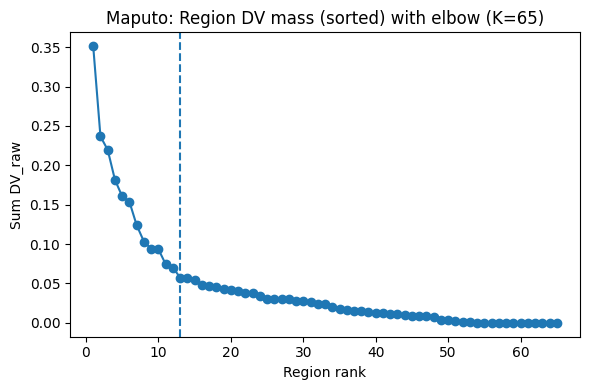

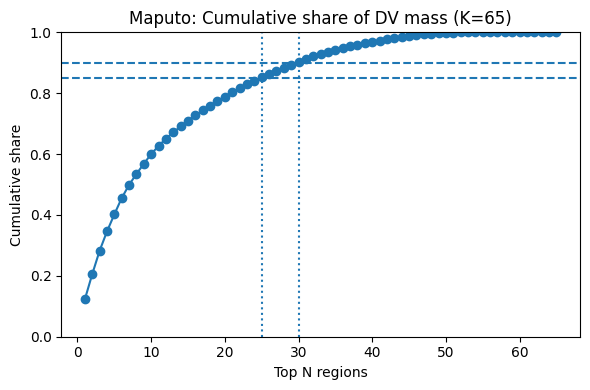

Elbow ≈ Top 13 regions (mass cutoff ≈ 0.0575).
Top 25 regions ≈ 85% of DV mass.
Top 30 regions ≈ 90% of DV mass.

Selected region lists (ids):
  elbow: [13, 21, 11, 40, 46, 60, 43, 12, 28, 45, 39, 41, 19] 
  85%  : [13, 21, 11, 40, 46, 60, 43, 12, 28, 45, 39, 41, 19, 23, 5, 2, 55, 52, 42, 54] ...
  90%  : [13, 21, 11, 40, 46, 60, 43, 12, 28, 45, 39, 41, 19, 23, 5, 2, 55, 52, 42, 54] ...


In [ ]:
# ---- ELBOW ON REGION MASS (Maputo, K_REG=95) ----
import numpy as np
import matplotlib.pyplot as plt

CITY    = "Maputo"   # titles only
K_REG   = 65
USE_LOGY = False      # Maputo is smaller; turn on if mass is very heavy-tailed
PCT_LINES = (0.85, 0.90)

# Point to the right region column
REG_COL = globals().get("REG_COL", f"region_k{K_REG}")
if REG_COL not in gdf.columns:
    candidates = [c for c in gdf.columns if c.startswith("region_k")]
    if len(candidates) == 1:
        REG_COL = candidates[0]
    else:
        raise KeyError(f"Region column '{REG_COL}' not found. Candidates: {candidates}")

# Sum DV by region and sort descending
mass = (gdf.groupby(REG_COL)["DV_raw"]
          .sum()
          .sort_values(ascending=False))
vals  = mass.values
ranks = np.arange(1, len(vals) + 1)

if vals.sum() == 0 or len(vals) < 2:
    print("Not enough or zero DV mass to compute an elbow.")
else:
    # Elbow via max distance to the line from first to last point
    p1 = np.array([ranks[0],  vals[0]])
    p2 = np.array([ranks[-1], vals[-1]])
    v  = p2 - p1
    vnorm = np.linalg.norm(v)
    pts = np.column_stack([ranks, vals])
    dists = (np.abs(np.cross(v, pts - p1)) / vnorm) if vnorm > 0 else np.abs(vals - vals[0])
    elbow_idx = int(np.argmax(dists))
    elbow_k   = elbow_idx + 1
    cutoff    = vals[elbow_idx]

    # Cumulative share helpers (e.g., 85% / 90%)
    cumshare = np.cumsum(vals) / vals.sum()
    kP = {int(p*100): int(np.searchsorted(cumshare, p)) + 1 for p in PCT_LINES}

    # 1) Mass (sorted) + elbow
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, vals, marker='o')
    plt.axvline(elbow_k, linestyle='--')
    if USE_LOGY:
        plt.yscale("symlog")
    plt.title(f"{CITY}: Region DV mass (sorted) with elbow (K={K_REG})")
    plt.xlabel("Region rank")
    plt.ylabel("Sum DV_raw")
    plt.tight_layout()
    plt.show()

    # 2) Cumulative share curve
    plt.figure(figsize=(6, 4))
    plt.plot(ranks, cumshare, marker='o')
    for p in PCT_LINES:
        plt.axhline(p, linestyle='--')
        plt.axvline(kP[int(p*100)], linestyle=':')
    plt.ylim(0, 1)
    plt.title(f"{CITY}: Cumulative share of DV mass (K={K_REG})")
    plt.xlabel("Top N regions")
    plt.ylabel("Cumulative share")
    plt.tight_layout()
    plt.show()

    # Lists to use downstream
    top_regions_elbow = mass.index[:elbow_k].tolist()
    top_regions_85    = mass.index[:kP.get(85, 0)].tolist()
    top_regions_90    = mass.index[:kP.get(90, 0)].tolist()

    print(f"Elbow ≈ Top {elbow_k} regions (mass cutoff ≈ {cutoff:.3g}).")
    if 85 in kP: print(f"Top {kP[85]} regions ≈ 85% of DV mass.")
    if 90 in kP: print(f"Top {kP[90]} regions ≈ 90% of DV mass.")
    print("\nSelected region lists (ids):")
    print("  elbow:", top_regions_elbow[:20], "..." if len(top_regions_elbow) > 20 else "")
    print("  85%  :", top_regions_85[:20],    "..." if len(top_regions_85) > 20 else "")
    print("  90%  :", top_regions_90[:20],    "..." if len(top_regions_90) > 20 else "")

    # Default choice for downstream steps:
    top_regions = top_regions_elbow


In [ ]:
import math, warnings, json
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree
from libpysal.weights import KNN
from esda.moran import Moran

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Maputo"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "moz_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 65               # Maputo: 65 regions
TOP_K    = 30               # analyze top-30 regions by DV mass
GLOBAL_SAMPLE_N = 20_000
RANDOM_SEED = 42

RF_GLOBAL = dict(n_estimators=600, max_depth=20, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5, random_state=RANDOM_SEED, n_jobs=-1)

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def dv_stratified_sample(gdf, dv_col, n, q=10, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    g = gdf.copy()
    pos = g[g["DV_raw"] > 0].copy()
    zero = g[g["DV_raw"] == 0].copy()
    parts = []
    if len(pos) > 0:
        pos["dv_dec"] = pd.qcut(pos[dv_col], q=q, duplicates="drop")
        n_pos = min(len(pos), n // 2)
        if n_pos > 0:
            take_per_bin = max(1, n_pos // pos["dv_dec"].nunique())
            parts.append(pos.groupby("dv_dec", group_keys=False)
                           .apply(lambda d: d.sample(min(len(d), take_per_bin), random_state=seed)))
    else:
        n_pos = 0
    n_zero = n - n_pos
    if len(zero) > 0 and n_zero > 0:
        parts.append(zero.sample(min(len(zero), n_zero), random_state=seed))
    out = pd.concat(parts) if parts else g.head(min(n, len(g)))
    return out

def perm_importance_table(model, X, y, feature_names, n_repeats=10, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats, random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names, "imp_mean": r.importances_mean, "imp_std": r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def blocked_cv_global(X, y, coords, groups, rf_params, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    y_true_all, y_pred_all, morans = [], [], []
    for fold, (tr, te) in enumerate(gkf.split(X, y, groups=groups), 1):
        rf = RandomForestRegressor(**rf_params)
        rf.fit(X[tr], y[tr])
        pred = rf.predict(X[te])
        y_true_all.append(y[te]); y_pred_all.append(pred)
        resid = y[te] - pred
        w = KNN.from_array(coords[te], k=8); w.transform = 'r'
        mi = Moran(resid, w)
        morans.append(dict(fold=fold, I=float(mi.I), p=float(mi.p_sim)))
    y_true_all = np.concatenate(y_true_all); y_pred_all = np.concatenate(y_pred_all)
    metrics = dict(r2=float(r2_score(y_true_all, y_pred_all)),
                   mae=float(mean_absolute_error(y_true_all, y_pred_all)))
    return metrics, pd.DataFrame(morans), y_true_all, y_pred_all

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing: print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-30 =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= GLOBAL RF (blocked CV) =========================
gdf_global = dv_stratified_sample(gdf, DV_COL, n=GLOBAL_SAMPLE_N, q=10, seed=RANDOM_SEED)

X_global = gdf_global[PRED_USE].values
y_global = gdf_global[DV_COL].values
coords_global = gdf_global[["x_utm","y_utm"]].values
groups_global = gdf_global["region"].values

scaler = StandardScaler().fit(X_global)
Xg_scaled = scaler.transform(X_global)

rf_global = RandomForestRegressor(**RF_GLOBAL)
rf_global.fit(Xg_scaled, y_global)

global_imp = perm_importance_table(rf_global, Xg_scaled, y_global, PRED_USE, n_repeats=10, seed=RANDOM_SEED)
cv_metrics, morans_df, y_true_cv, y_pred_cv = blocked_cv_global(Xg_scaled, y_global, coords_global, groups_global, RF_GLOBAL, n_splits=5)

print("\n=== GLOBAL RF ===")
print("Permutation importance (top 10):")
print(global_imp.head(10).to_string(index=False))
print("\nBlocked-CV metrics:", json.dumps(cv_metrics, indent=2))
print("\nMoran's I of test residuals by fold:")
print(morans_df.to_string(index=False))

# ========================= PER-REGION RFs (Top-30) =========================
region_reports, region_imps = [], []

for rid in top_regions:
    sub = gdf[gdf["region"] == rid]
    if len(sub) < 500:
        continue
    Xr = sub[PRED_USE].values
    yr = sub[DV_COL].values
    scaler_r = StandardScaler().fit(Xr)
    Xr_s = scaler_r.transform(Xr)

    rf_r = RandomForestRegressor(**RF_REGION)
    rf_r.fit(Xr_s, yr)

    imp_r = perm_importance_table(rf_r, Xr_s, yr, PRED_USE, n_repeats=8, seed=RANDOM_SEED)
    imp_r["region"] = rid
    region_imps.append(imp_r)

    r2 = rf_r.score(Xr_s, yr)
    region_reports.append(dict(region=rid, n=len(sub), r2=float(r2)))

region_reports = pd.DataFrame(region_reports).sort_values("region")
region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

print("\n=== PER-REGION RFs (Top-30 by mass) ===")
print(region_reports.to_string(index=False) if not region_reports.empty else "No regions met size requirement.")

if not region_imps_df.empty:
    het = (region_imps_df.groupby("feature")["imp_mean"]
           .agg(["mean","std"])
           .rename(columns={"mean":"imp_mean","std":"imp_std"})
           .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0,np.nan))))
    het = het.sort_values("cv", ascending=False)
    print("\nImportance heterogeneity across Top-30 (sorted by CV):")
    print(het.round(3).to_string())
else:
    print("\n(Per-region importance table is empty.)")


[Maputo] Loaded 319,048 rows | UTM EPSG:32736 | non-zero DV: 72,424
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'moz_general_2020']
Top-30 regions by DV mass: [13, 21, 11, 40, 46, 60, 43, 12, 28, 45] ...

=== GLOBAL RF ===
Permutation importance (top 10):
                    feature  imp_mean  imp_std
        accessibility_index  0.627896 0.009304
               ntl_bilinear  0.436920 0.013222
           dist_secondary_m  0.385458 0.009544
      spacing_median_m_250m  0.315387 0.004959
                 rwi_interp  0.309625 0.011677
mean_footprint_area_m2_250m  0.242023 0.004197
           moz_general_2020  0.141084 0.004677
            dist_tertiary_m  0.060716 0.001217
               slum_mean30m  0.058668 0.001754
    

In [ ]:
import math, warnings
import numpy as np, pandas as pd, geopandas as gpd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# ========================= CONFIG =========================
CITY = "Maputo"
CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

PREDICTORS = [
    "rwi_interp","ntl_bilinear","slum_mean30m","mean_footprint_area_m2_250m",
    "accessibility_index","spacing_median_m_250m","orientation_dispersion_250m",
    "u18_bilinear","built_environment_index",
    "dist_secondary_m","dist_tertiary_m","clark_evans_R_net_250m","dist_to_mask_edge_m_250m", "moz_general_2020"
]
DV_COL   = "DV_log1p"
K_REG    = 65               # Maputo: 65 regions
TOP_K    = 30               # analyze top-K regions by DV mass
RANDOM_SEED = 42

# Local RF params (only local results requested)
RF_REGION = dict(n_estimators=400, max_depth=18, min_samples_split=5,
                 random_state=RANDOM_SEED, n_jobs=-1)

# ---------------- MULTI-RUN NEIGHBOURHOOD AREAS (km^2) ----------------
MAX_AREA_LIST_KM2 = [3.0, 2.0, 1.0]
GRID_RES_M   = 30
MIN_PIXELS   = 500

# ========================= HELPERS =========================
def utm_epsg_for_lonlat(lon, lat):
    zone = int(math.floor((lon + 180)/6) + 1)
    return f"EPSG:{32600+zone if lat >= 0 else 32700+zone}"

def perm_importance_table(model, X, y, feature_names, n_repeats=8, seed=RANDOM_SEED):
    r = permutation_importance(model, X, y, n_repeats=n_repeats,
                               random_state=seed, n_jobs=-1)
    df = pd.DataFrame({"feature": feature_names,
                       "imp_mean": r.importances_mean,
                       "imp_std":  r.importances_std})
    return df.sort_values("imp_mean", ascending=False).reset_index(drop=True)

def apply_neighbourhood_cap(sub, max_radius_m, max_pixels,
                            min_pixels=MIN_PIXELS, seed=RANDOM_SEED,
                            x_col="x_utm", y_col="y_utm"):
    """Cap subset to a circular neighbourhood around its centroid; then apply pixel-count backstop."""
    if sub.empty:
        return None

    cx, cy = sub[[x_col, y_col]].mean().values
    dist = np.sqrt((sub[x_col] - cx)**2 + (sub[y_col] - cy)**2)
    capped = sub.loc[dist <= max_radius_m].copy()

    if len(capped) < min_pixels:
        return None

    if len(capped) > max_pixels:
        capped = capped.sample(max_pixels, random_state=seed)

    return capped

def run_local_rf_for_area(gdf, pred_use, top_regions, max_area_km2):
    """Run local RFs for a given neighbourhood max area; return per-region report + heterogeneity table."""
    max_radius_m = float(np.sqrt((max_area_km2 * 1e6) / np.pi))
    max_pixels   = int((max_area_km2 * 1e6) / (GRID_RES_M * GRID_RES_M))

    print(f"\n--- Local RF: MAX_AREA_KM2={max_area_km2:.1f} "
          f"(radius≈{max_radius_m:.0f} m, max_pixels≈{max_pixels:,}) ---")

    region_reports, region_imps = [], []

    for rid in top_regions:
        sub0 = gdf[gdf["region"] == rid]
        sub  = apply_neighbourhood_cap(sub0, max_radius_m=max_radius_m, max_pixels=max_pixels)
        if sub is None:
            continue

        Xr = sub[pred_use].values
        yr = sub[DV_COL].values

        scaler_r = StandardScaler().fit(Xr)
        Xr_s = scaler_r.transform(Xr)

        rf_r = RandomForestRegressor(**RF_REGION)
        rf_r.fit(Xr_s, yr)

        imp_r = perm_importance_table(rf_r, Xr_s, yr, pred_use, n_repeats=8, seed=RANDOM_SEED)
        imp_r["region"] = rid
        imp_r["n_used"] = len(sub)
        imp_r["radius_m"] = max_radius_m
        imp_r["max_area_km2"] = max_area_km2
        region_imps.append(imp_r)

        r2 = rf_r.score(Xr_s, yr)  # in-sample diagnostic
        region_reports.append(dict(region=rid, n_used=len(sub), r2=float(r2)))

    region_reports_df = pd.DataFrame(region_reports).sort_values("region") if region_reports else pd.DataFrame()
    region_imps_df = pd.concat(region_imps, ignore_index=True) if region_imps else pd.DataFrame()

    if not region_imps_df.empty:
        het = (region_imps_df
               .groupby("feature")["imp_mean"]
               .agg(["mean","std"])
               .rename(columns={"mean":"imp_mean","std":"imp_std"})
               .assign(cv=lambda d: d["imp_std"].div(d["imp_mean"].replace(0, np.nan))))
        het = het.sort_values("cv", ascending=False).reset_index()
        het["max_area_km2"] = max_area_km2
    else:
        het = pd.DataFrame()

    return region_reports_df, region_imps_df, het

# ========================= LOAD & PROJECT =========================
df = pd.read_csv(CSV, low_memory=False)
assert {"longitude","latitude",DV_COL}.issubset(df.columns), "CSV must include longitude, latitude, DV column."
epsg = utm_epsg_for_lonlat(df["longitude"].mean(), df["latitude"].mean())

gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                       crs="EPSG:4326").to_crs(epsg)
gdf["x_utm"], gdf["y_utm"] = gdf.geometry.x, gdf.geometry.y
gdf["DV_raw"] = np.expm1(gdf[DV_COL])

print(f"[{CITY}] Loaded {len(gdf):,} rows | UTM {epsg} | non-zero DV: {(gdf['DV_raw']>0).sum():,}")

# Adapt predictors to what's available
missing = [c for c in PREDICTORS if c not in gdf.columns]
present = [c for c in PREDICTORS if c in gdf.columns]
if missing:
    print(f"Missing predictors (skipped): {missing}")
print(f"Using {len(present)} predictors: {present}")
PRED_USE = present

# ========================= K-MEANS REGIONS & TOP-K =========================
km = KMeans(n_clusters=K_REG, random_state=RANDOM_SEED, n_init=10)
gdf["region"] = km.fit_predict(gdf[["x_utm","y_utm"]].values)

mass = gdf.groupby("region")["DV_raw"].sum().sort_values(ascending=False)
top_regions = mass.head(TOP_K).index.tolist()
print(f"Top-{TOP_K} regions by DV mass:", top_regions[:10], "..." if len(top_regions)>10 else "")

# ========================= LOCAL RF: RUN FOR 3/2/1 km² =========================
all_region_reports = []
all_heterogeneity = []
all_region_imps = []

for a in MAX_AREA_LIST_KM2:
    rep_df, imps_df, het_df = run_local_rf_for_area(gdf, PRED_USE, top_regions, max_area_km2=a)

    print("\nPer-region diagnostics (r2 is in-sample):")
    print(rep_df.to_string(index=False) if not rep_df.empty else "No regions met size requirement after capping.")

    print("\nImportance heterogeneity (sorted by CV):")
    if not het_df.empty:
        print(het_df[["feature","imp_mean","imp_std","cv","max_area_km2"]].round(3).to_string(index=False))
    else:
        print("(Empty)")

    # store outputs
    if not rep_df.empty:
        rep_df = rep_df.copy()
        rep_df["max_area_km2"] = a
        all_region_reports.append(rep_df)
    if not het_df.empty:
        all_heterogeneity.append(het_df)
    if not imps_df.empty:
        all_region_imps.append(imps_df)

# ========================= OPTIONAL: COMBINED TABLES =========================
combined_region_reports = pd.concat(all_region_reports, ignore_index=True) if all_region_reports else pd.DataFrame()
combined_heterogeneity  = pd.concat(all_heterogeneity, ignore_index=True) if all_heterogeneity else pd.DataFrame()
combined_region_imps    = pd.concat(all_region_imps, ignore_index=True) if all_region_imps else pd.DataFrame()

print("\n\n=== COMBINED HETEROGENEITY (all areas) ===")
if not combined_heterogeneity.empty:
    print(combined_heterogeneity[["max_area_km2","feature","imp_mean","imp_std","cv"]]
          .sort_values(["max_area_km2","cv"], ascending=[False, False])
          .round(3).to_string(index=False))
else:
    print("(Empty)")

# ========================= OPTIONAL: SAVE OUTPUTS =========================
# outdir = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Local_RF_Sensitivity"
# Path(outdir).mkdir(parents=True, exist_ok=True)
# combined_region_reports.to_csv(f"{outdir}/{CITY.lower()}_localrf_region_reports_3_2_1km2.csv", index=False)
# combined_heterogeneity.to_csv(f"{outdir}/{CITY.lower()}_localrf_heterogeneity_3_2_1km2.csv", index=False)
# combined_region_imps.to_csv(f"{outdir}/{CITY.lower()}_localrf_importances_by_region_3_2_1km2.csv", index=False)


[Maputo] Loaded 319,048 rows | UTM EPSG:32736 | non-zero DV: 72,424
Using 14 predictors: ['rwi_interp', 'ntl_bilinear', 'slum_mean30m', 'mean_footprint_area_m2_250m', 'accessibility_index', 'spacing_median_m_250m', 'orientation_dispersion_250m', 'u18_bilinear', 'built_environment_index', 'dist_secondary_m', 'dist_tertiary_m', 'clark_evans_R_net_250m', 'dist_to_mask_edge_m_250m', 'moz_general_2020']
Top-30 regions by DV mass: [13, 21, 11, 40, 46, 60, 43, 12, 28, 45] ...

--- Local RF: MAX_AREA_KM2=3.0 (radius≈977 m, max_pixels≈3,333) ---

Per-region diagnostics (r2 is in-sample):
 region  n_used       r2
      0    1754 0.996744
      2    2920 0.996936
      5    3228 0.998603
     11    2595 0.996287
     12    3177 0.998697
     13    3333 0.998493
     14    2636 0.994229
     19    3138 0.997646
     21    2157 0.994375
     23    2487 0.995451
     28    2935 0.997992
     31    2743 0.996198
     36    2642 0.997722
     37    1178 0.995892
     39    1568 0.997950
     40    256